# Notebook for analysis of bulk RNAseq data in BULLKpy
## Notebook 3. Differential expression, pathway and survival analysis
@mmm, November 4, 2026

<div style="font-size: 24px; line-height: 1.1">
Notebook Menu

<div style="font-size: 18px; line-height: 1.4">
<a href="#imports">1. Imports and settings</a><br>
<a href="#loads">2. Load the H5AD object</a><br>
<a href="#de">3. Markers and Differential Expression</a><br>
<a href="#go">4. Pathway and Gene Enrichment Analysis</a><br>
<a href="#mp">5. Metaprograms and Tumor Heterogeneity</a><br>
<a href="#survival">6. Survival analysis</a><br>


# 1. Imports and settings
<a id="imports"></a>

## 1.1. Modules and Settings

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

import anndata as ad
import bullkpy as bk

import gseapy as gspy
from gseapy import Msigdb
from gseapy import gseaplot
from gseapy import enrichment_map

In [2]:
import sys
sys.version
print("Python:", sys.version, "Numpy:", np.__version__, "Pandas:", pd.__version__, "Matplotlib:", mpl.__version__, "Seaborn:", sns.__version__, 
      "AnnData:", ad.__version__, "GSEApy:", gspy.__version__)

Python: 3.12.13 (main, May 10 2026, 19:20:41) [Clang 22.1.3 ] Numpy: 2.4.6 Pandas: 3.0.5 Matplotlib: 3.11.1 Seaborn: 0.13.2 AnnData: 0.13.2 GSEApy: 1.3.1


In [3]:
bk.settings.verbosity = 3
bk.settings.plot_theme = "paper"      # "default" | "paper" | "talk"
bk.settings.plot_palette = "Set1"
bk.settings.plot_fontsize = 10        # optional
bk.settings.plot_dpi = 200
bk.settings.save_dpi = 300

# every plot calls set_style() internally, or you can call once:
bk.pl.set_style()
pal = sns.color_palette("husl", n_colors=35)       # palette for large categories
bk.settings.set_palette_for("Project_ID", where="obs", palette="husl")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="lifelines")

Change to paths with your files:

In [4]:
# Point these at your own copies of the public source data.

DATA = "../data/"
DATA_EXTERNAL = "../data/external/"
DATA_H5AD = '../data/h5ad/'

RESULTS = "../results/"
FIGURES = "../results/figs/"
TABLES = "../results/tables/"
GSEA = "../results/gsea/"

import os
for _p in (DATA, DATA_EXTERNAL):
    if not os.path.isdir(_p):
        print(f"WARNING: {_p} not found - update DATA above before running section 2.")

# Single source of truth for the objects this notebook builds, so every save and
# reload below refers to the same file.

H5AD      = DATA_H5AD + "TCGA_lung.h5ad"


# 2. Load data into AnnData and BULLKpy object
<a id="loads"></a>

In [5]:
## 2.1. Load the .h5ad object

adata = ad.read_h5ad(H5AD)
adata 

AnnData object with n_obs × n_vars = 1108 × 31891
    obs: 'Sample_ID', 'Patient_ID', 'Project_ID', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'histological_type', 'initial_pathologic_dx_year', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'new_tumor_event_type', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Subtype_mRNA', 'Subtype_DNAmeth', 'Subtype_Integrative', 'Subtype_Selected', 'sample_type_id', 'sample_type', '_primary_disease', 'Subtype_Immune_Model_Based', 'ICS5_score', 'LIexpression_score', 'Chemokine12_score', 'NHI_5gene_score', 'CD68', 'CD8A', 'PD1_data', 'PDL1_data', 'PD1_PDL1_score', 'CTLA4_data', 'Bcell_mg_IGJ', 'Bcell_receptors_score', 'STAT1_score', 'CSF1_response', 'TcClassII_score', 'IL12_score_21050467', 'IL4_score_21050467', 'IL2_score_21050467', 'IL13_score_21050467', 'IFNG_score_21050467', 'TGFB_score_21050467', 'TREM1_dat

# 3. Markers and Differential expression
<a id="de"></a>

## 3.1. Marker genes

Which genes are differentially expressed between groups?  
Based on Differential expression (DE). Similar to Scanpy rank_genes_groups (group vs rest, etc.)
#rank_genes_groups

### 3.1.1. Every groups versus the rest

In [6]:
#Everyone versus the rest
bk.tl.rank_genes_groups(
    adata,
    groupby="Project_ID",
    layer="log1p_cpm",
    method="t-test",
    n_genes=50,
)

In [7]:
# Get the results for a group
df_lumb = bk.get.rank_genes_groups_df(adata, group="LUAD", sort_by="scores")
df_lumb.head()

,gene,scores,log2FC,pval,qval,mean_group,mean_ref
0,ARHGEF38,37.065428,2.116427,9.674795e-173,2.804899e-169,2.365322,0.898327
1,HNF1B,36.789241,2.864644,1.054959e-186,5.607284e-183,2.746731,0.761112
2,RORC,36.272704,2.920038,3.156899e-181,1.118630e-177,3.378414,1.354398
3,NKX2-1-AS1,33.920713,1.896274,1.657560e-148,1.468368e-145,1.685101,0.370704
4,GPR39,33.820763,1.926468,1.624700e-153,1.727110e-150,2.192588,0.857262


In [8]:
# Get the results for all groups
df_all = bk.get.rank_genes_groups_df_all(adata)
df_all.head()

,group,gene,scores,log2FC,pval,qval,mean_group,mean_ref
0,LUAD,ARHGEF38,37.065428,2.116427,9.674795e-173,2.804899e-169,2.365322,0.898327
1,LUAD,HNF1B,36.789241,2.864644,1.054959e-186,5.607284e-183,2.746731,0.761112
2,LUAD,RORC,36.272704,2.920038,3.156899e-181,1.118630e-177,3.378414,1.354398
3,LUAD,NKX2-1-AS1,33.920713,1.896274,1.657560e-148,1.468368e-145,1.685101,0.370704
4,LUAD,GPR39,33.820763,1.926468,1.624700e-153,1.727110e-150,2.192588,0.857262


In [9]:
# export
df_all.to_csv(TABLES + "rank_genes_groups_all.tsv", sep="\t", index=False)

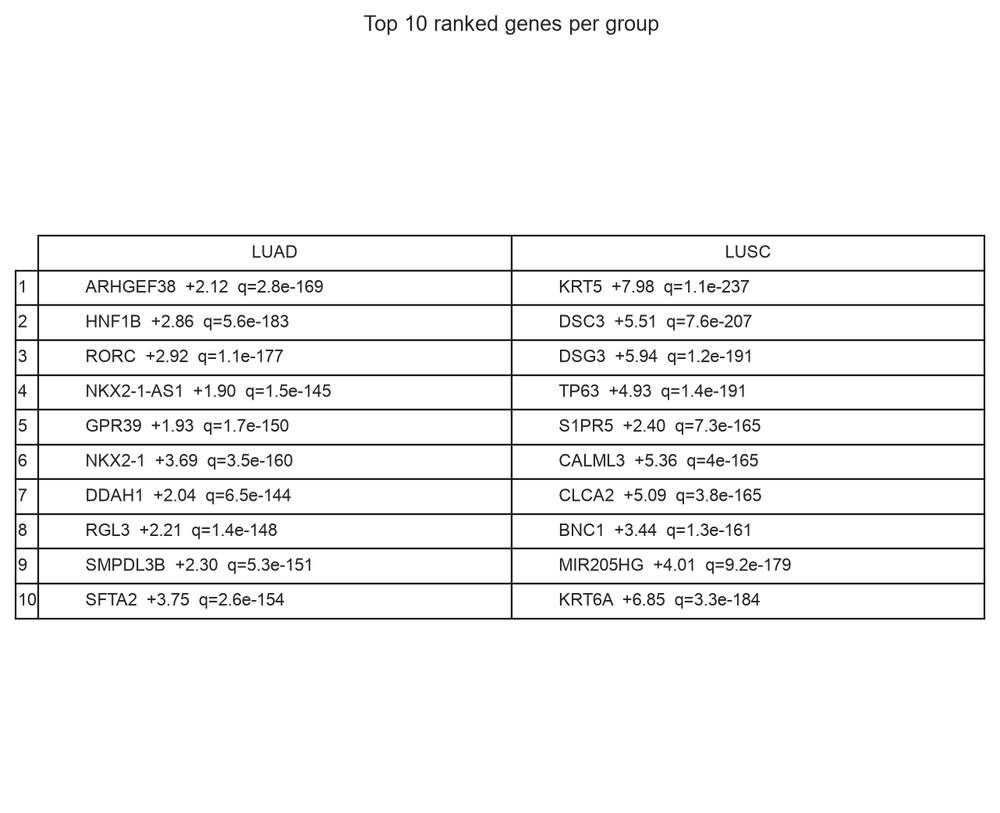

(<Figure size 1300x1060 with 1 Axes>,
 <Axes: title={'center': 'Top 10 ranked genes per group'}>)

In [10]:
# Quick table view
bk.pl.rank_genes_groups(adata, n_genes=10, 
                        save=FIGURES + "rank_genes_groups_table.png")

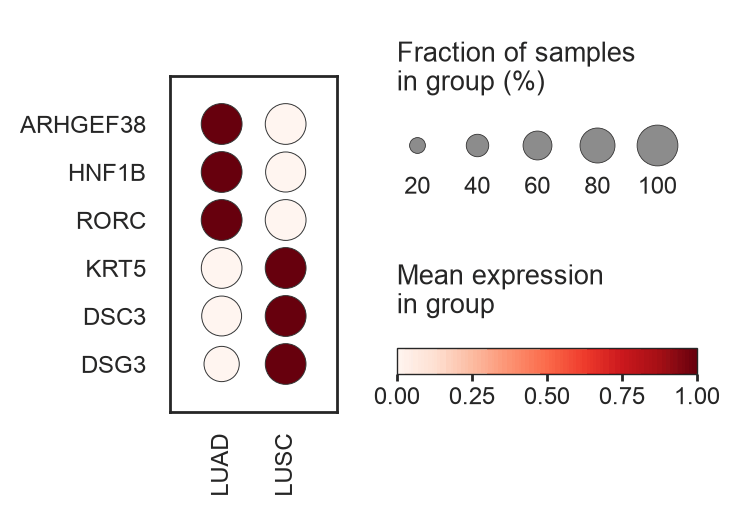

(<Figure size 687.2x479.267 with 3 Axes>, <Axes: >)

In [11]:
#3. Dotplot of top markers per group

bk.pl.rank_genes_groups_dotplot(
    adata,
    groupby="Project_ID",
    n_genes=3,
    swap_axes=True,
    dendrogram_top=True,
    #figsize=(4,4),
    #save=FIGURES + "rank_genes_groups_dotplot.png",
)

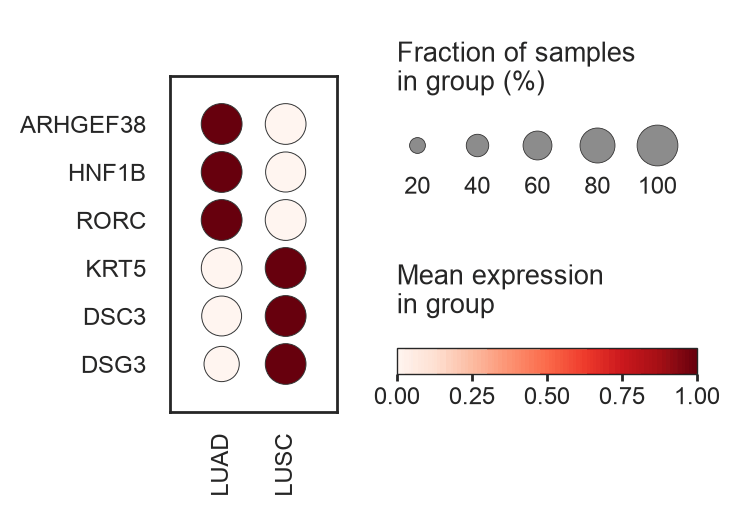

(<Figure size 687.2x479.267 with 3 Axes>, <Axes: >)

In [12]:
bk.pl.rank_genes_groups_dotplot(
    adata,
    groupby="Project_ID",
    n_genes=3,
    swap_axes=True,
    dendrogram_top=True,
    dendrogram_rows=False,
    #save=FIGURES + "rank_genes_groups_dotplot.png",
)

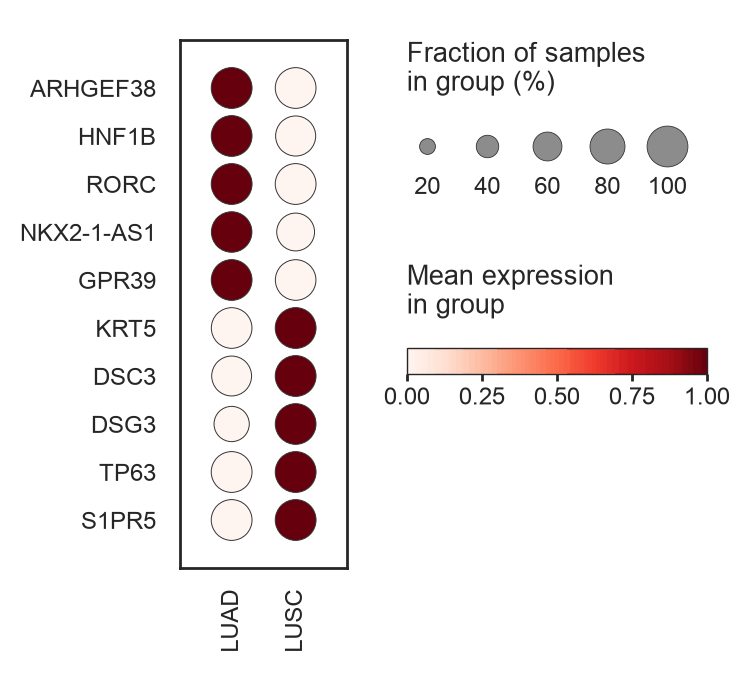

(<Figure size 697.2x635 with 3 Axes>, <Axes: >)

In [13]:
#A. Scanpy-like expression dotplot (auto standard_scale=“var”)
bk.pl.rank_genes_groups_dotplot(
    adata,
    groupby="Project_ID",
    n_genes=5,
    values_to_plot="expression",
    standard_scale="auto",
    #save=FIGURES + "rgg_dotplot_expression.png",
)

### 3.1.2. One group or a few groups versus other group

In [14]:
# Group versus specific reference
bk.tl.rank_genes_groups(
    adata,
    groupby="Subtype_mRNA",
    groups=["secretory", "basal"],
    reference="primitive",
    layer="log1p_cpm",
    method="wilcoxon",
    n_genes=50,
)

Get the genes from `adata.uns['rank_genes_groups']` into a dataframe

In [15]:
df_lumb = bk.get.rank_genes_groups_df(adata, group="basal", sort_by="scores") 
df_lumb.head()

,gene,scores,log2FC,pval,qval,mean_group,mean_ref
0,S100A9,6.627105,4.842156,3.568802e-11,0.000001,7.018562,3.662235
1,S100A8,6.516448,5.091558,7.500058e-11,0.000001,5.799385,2.270186
2,SERPINB3,6.307430,4.543113,2.951929e-10,0.000002,4.566094,1.417048
3,TGM1,6.282840,2.870391,3.458521e-10,0.000002,2.910345,0.920742
4,IL36G,6.270544,2.674057,3.742712e-10,0.000002,2.200759,0.347244


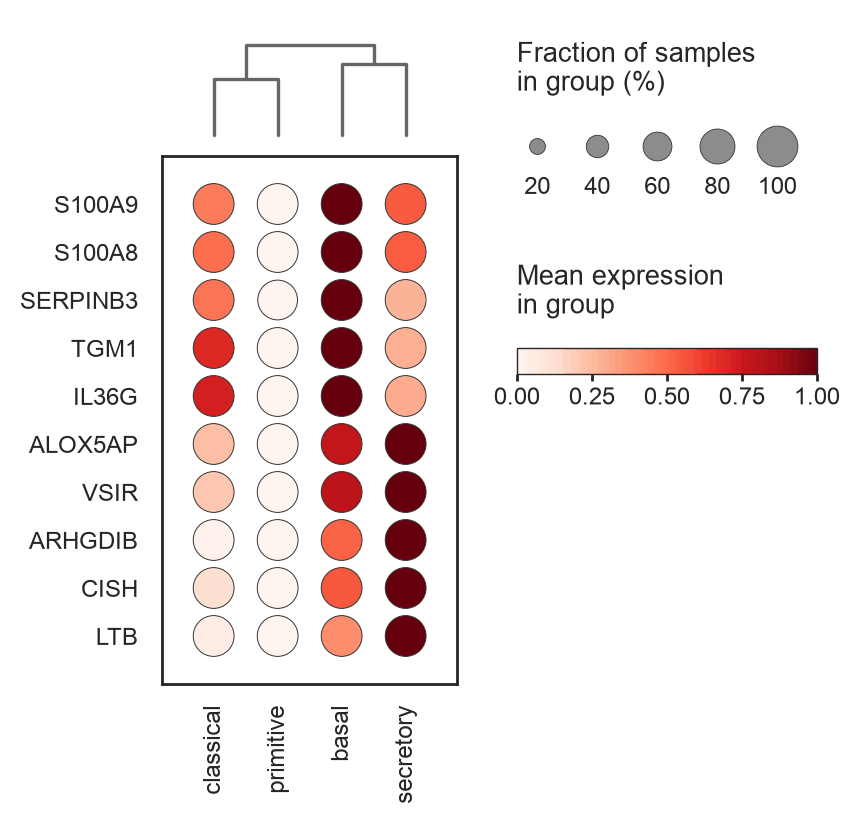

(<Figure size 807.2x786 with 4 Axes>, <Axes: >)

In [16]:
#A. Scanpy-like expression dotplot (auto standard_scale=“var”)
bk.pl.rank_genes_groups_dotplot(
    adata,
    groupby="Subtype_mRNA",
    n_genes=5,
    values_to_plot="expression",
    
    standard_scale="auto",
    #save=FIGURES + "rgg_dotplot_expression.png",
)

## 3.2. Differential expression

For bulk RNA-seq, the two most useful layers are:  
	•	a fast exploratory DE (like Scanpy’s “rank genes” idea) → Welch t-test on log1p_cpm  
	•	a proper bulk model → Negative Binomial GLM (DESeq2/edgeR spirit) on raw counts with library-size offset. Important: requires raw counts

Quick best-practice recommendation. Use:  
- Welch_ttest for fast exploration and ranking  
- NB GLM only if we either (a) estimate alpha properly, or (b) accept that it’s an approximate baseline  

#### Define comparison

In [17]:
adata.obs

,Sample_ID,Patient_ID,Project_ID,gender,race,ajcc_pathologic_tumor_stage,histological_type,initial_pathologic_dx_year,birth_days_to,vital_status,...,kmeans_25,kmeans_30,kmeans_5,Proliferation_score,T_cell_score,Neuroendocrine_score,NE25_score,S_score,G2M_score,phase
TCGA-97-7938-01A,TCGA-97-7938-01,TCGA-97-7938,LUAD,FEMALE,WHITE,Stage IA,Lung Adenocarcinoma,2011.0,-27980.0,Dead,...,2,11,3,-1.380975,-0.378700,-0.337587,-0.322850,-1.044417,-1.512500,G1
TCGA-55-7574-01A,TCGA-55-7574-01,TCGA-55-7574,LUAD,FEMALE,WHITE,Stage IB,Lung Adenocarcinoma,2011.0,-23703.0,Dead,...,3,27,3,-0.332047,1.581722,-0.452763,-0.170578,-0.710282,-0.387914,G1
TCGA-05-4250-01A,TCGA-05-4250-01,TCGA-05-4250,LUAD,FEMALE,NaN,Stage IIIA,Lung Adenocarcinoma,2007.0,-29068.0,Dead,...,8,7,3,0.356052,0.396601,0.007016,0.046466,0.412966,0.690445,G2M
TCGA-55-6979-11A,TCGA-55-6979-11,TCGA-55-6979,LUAD,FEMALE,WHITE,Stage IIB,Lung Adenocarcinoma,2006.0,-21780.0,Dead,...,5,26,0,-1.842698,0.898530,-0.457604,-0.136367,-1.465412,-1.718340,G1
TCGA-95-A4VK-01A,TCGA-95-A4VK-01,TCGA-95-A4VK,LUAD,FEMALE,WHITE,Stage IIIA,Lung Adenocarcinoma,2012.0,-27040.0,Alive,...,6,9,1,-0.600549,0.275623,-0.813417,-0.240207,-0.479216,-0.601463,G1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-77-8148-01A,TCGA-77-8148-01,TCGA-77-8148,LUSC,MALE,[Not Evaluated],Stage IIIA,Lung Squamous Cell Carcinoma,2006.0,-24918.0,Alive,...,0,29,4,0.962146,-0.715675,0.309586,0.224067,1.077761,0.814021,S
TCGA-39-5039-01A,TCGA-39-5039-01,TCGA-39-5039,LUSC,MALE,WHITE,Stage IIA,Lung Squamous Cell Carcinoma,2008.0,-27781.0,Dead,...,13,25,4,-0.042540,-0.334957,0.001901,-0.268950,0.230471,-0.011456,S
TCGA-43-8118-01A,TCGA-43-8118-01,TCGA-43-8118,LUSC,FEMALE,WHITE,Stage IA,Lung Squamous Cell Carcinoma,2011.0,-20224.0,Dead,...,12,0,4,0.980339,-0.904397,-0.386156,-0.231455,1.014476,0.524651,S
TCGA-43-6647-01A,TCGA-43-6647-01,TCGA-43-6647,LUSC,FEMALE,WHITE,Stage IIB,Lung Squamous Cell Carcinoma,2010.0,-25378.0,Alive,...,20,21,4,0.165791,0.061292,0.359028,0.064725,-0.364309,0.012148,G2M


In [18]:
# only primary
adata_tumor = adata[adata.obs["Sample_type"] == "Primary", :].copy()
adata_tumor

AnnData object with n_obs × n_vars = 1000 × 31891
    obs: 'Sample_ID', 'Patient_ID', 'Project_ID', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'histological_type', 'initial_pathologic_dx_year', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'new_tumor_event_type', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Subtype_mRNA', 'Subtype_DNAmeth', 'Subtype_Integrative', 'Subtype_Selected', 'sample_type_id', 'sample_type', '_primary_disease', 'Subtype_Immune_Model_Based', 'ICS5_score', 'LIexpression_score', 'Chemokine12_score', 'NHI_5gene_score', 'CD68', 'CD8A', 'PD1_data', 'PDL1_data', 'PD1_PDL1_score', 'CTLA4_data', 'Bcell_mg_IGJ', 'Bcell_receptors_score', 'STAT1_score', 'CSF1_response', 'TcClassII_score', 'IL12_score_21050467', 'IL4_score_21050467', 'IL2_score_21050467', 'IL13_score_21050467', 'IFNG_score_21050467', 'TGFB_score_21050467', 'TREM1_dat

Select column to select groups from and groups

In [19]:
adata_tumor.obs.RB1_mut = adata_tumor.obs.RB1_mut.astype("category")
adata_tumor.obs.RB1_mut.value_counts()

RB1_mut
0.0    912
1.0     58
Name: count, dtype: int64

In [20]:
dataset = adata_tumor                                    # adata, adata_lung
dataname = "Lung_tumor"                                  # TCGA, TCGA_lung
column = "RB1_mut"                                 # e,g, "Project_ID", "RB1_mut"
groupA = "1.0"                                     # e.g. "LUAD", "1.0"
groupB = "0.0"                                     # e.g. "LUSC", "0.0"

comparison = f"{column}_{groupA}_vs_{groupB}"
comparison

'RB1_mut_1.0_vs_0.0'

In [21]:
dataset = adata_tumor                                    # adata, adata_lung
dataname = "Lung_tumor"                                  # TCGA, TCGA_lung
column = "Project_ID"                                 # e,g, "Project_ID", "RB1_mut"
groupA = "LUSC"                                     # e.g. "LUAD", "1.0"
groupB = "LUAD"                                     # e.g. "LUSC", "0.0"

comparison = f"{column}_{groupA}_vs_{groupB}"
comparison

'Project_ID_LUSC_vs_LUAD'

### 3.2.1. Non-count based, log data: t-test, wilcoxon o welch t-test

In [22]:
# Fast exploratory (recommended first)
bk.tl.de(adata, groupby=column, group=groupA, reference=groupB,
    method="welch_ttest",         # wilcoxon  ---> explicitly non-count-based
    layer_expr="log1p_cpm",       # log
)

In [23]:
res = adata.uns["de"][comparison]["results"]
res.head(10)

,gene,log2FC,t,pval,qval,mean_group,mean_ref
15228,KRT5,7.984773,47.812033,1.122608e-242,3.580110e-238,6.897567,1.362944
6793,DSC3,5.506666,44.255097,2.723259e-212,4.342372e-208,4.443148,0.626218
1212,TP63,4.930373,39.040564,1.449537e-196,1.540906e-192,4.965646,1.548171
6789,DSG3,5.936904,43.800015,2.070914e-196,1.651088e-192,4.378563,0.263415
22542,ARHGEF38,-2.116427,-37.065429,3.896505e-196,2.485269e-192,0.898327,2.365322
30471,HNF1B,-2.864644,-36.789242,3.950869e-194,2.099953e-190,0.761112,2.746731
17337,KRT6A,6.854430,36.855229,3.082809e-188,1.404484e-184,6.375654,1.624525
8170,RORC,-2.920038,-36.272704,2.692960e-187,1.073515e-183,1.354398,3.378414
20911,MIR205HG,4.011205,37.191822,3.544951e-184,1.130520e-180,3.523598,0.743243
7336,TRIM29,4.548759,35.429467,3.427966e-184,1.130520e-180,5.177550,2.024591


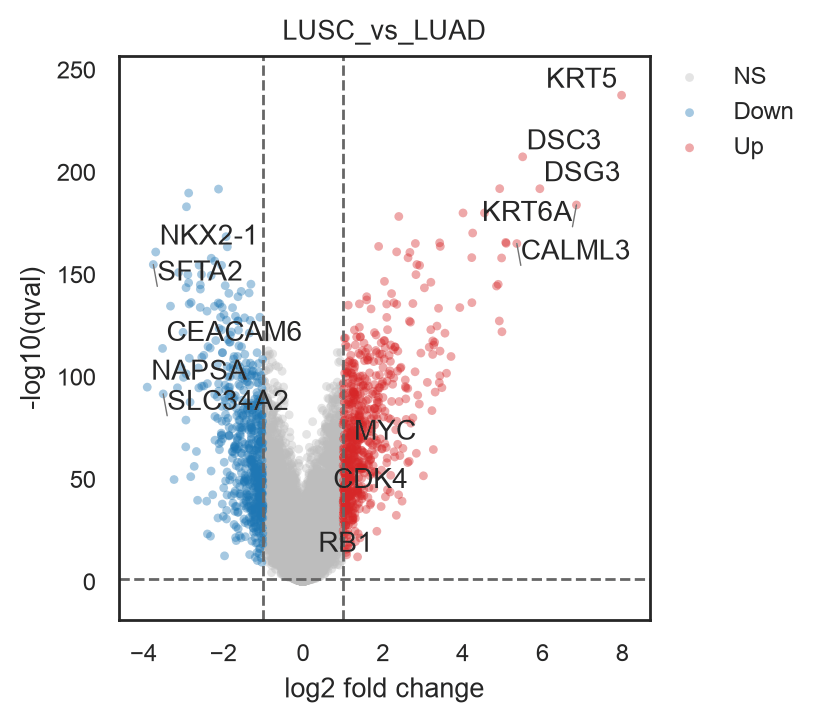

(<Figure size 800x700 with 1 Axes>,
 <Axes: title={'center': 'LUSC_vs_LUAD'}, xlabel='log2 fold change', ylabel='-log10(qval)'>)

In [24]:
bk.pl.volcano(res, title="LUSC_vs_LUAD", 
              alpha=0.4,
              top_n_labels = 5,                             # int
              bottom_n_labels = 5,
              label_genes = ["RB1", "MYC", "CDK4"],        #: Sequence[str] = (),
              label_offset=(0.1, 0.8),
              p_cutoff = 0.05,
              fc_cutoff = 1.0,              # optional, set >0 to require |log2FC| >= fc_cutoff
              point_size=10,
              figsize=(4,3.5),
              save= FIGURES + "volcano.png"
             )

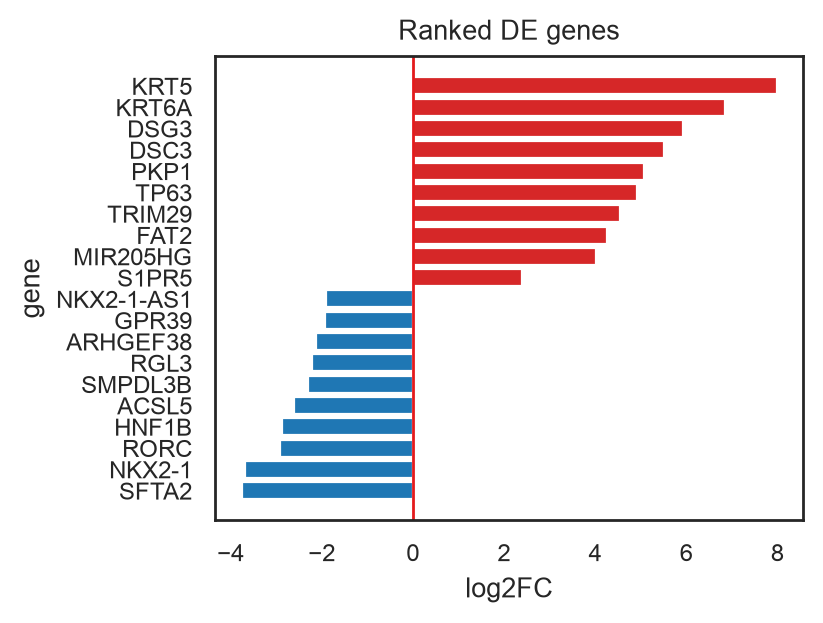

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Ranked DE genes'}, xlabel='log2FC', ylabel='gene'>)

In [25]:
bk.pl.rankplot(res=res, n_genes=20, 
               direction="both", 
               sort_by="qval",               # or pval or log2FC
               figsize=(4, 3),
              )       #save=FIGURES + "rankplot.png"

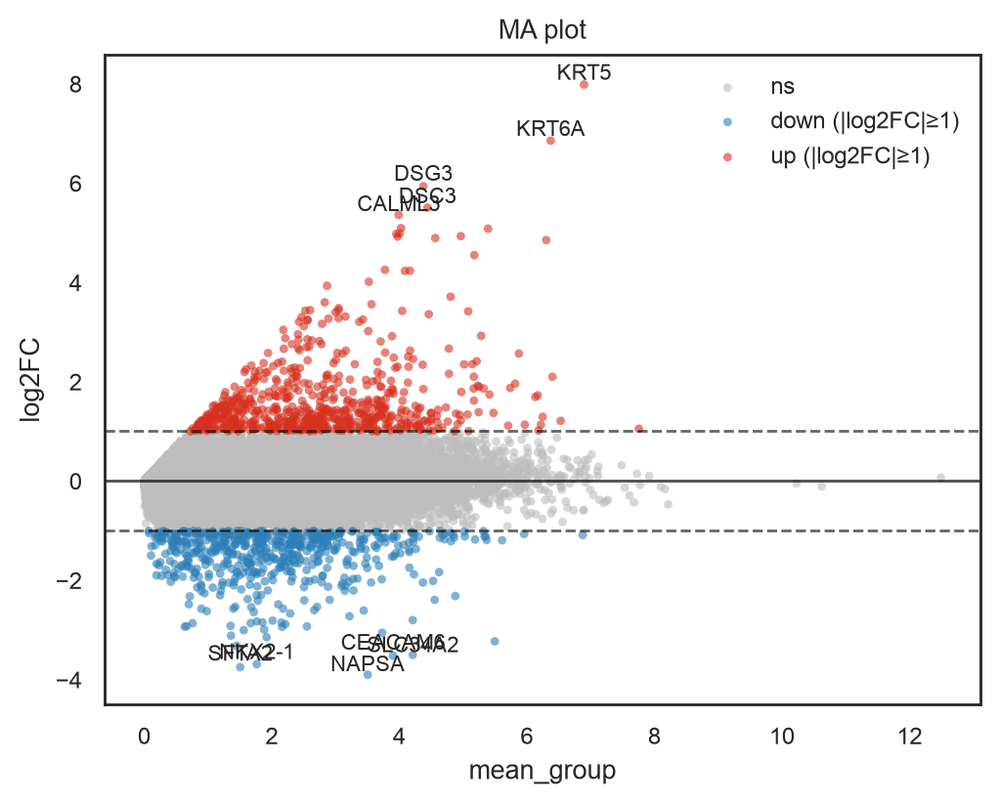

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'MA plot'}, xlabel='mean_group', ylabel='log2FC'>)

In [26]:
bk.pl.ma(
    result=res,
    mean_col="mean_group",
    fc_col="log2FC",
    top_n_labels=5,
    bottom_n_labels=5,
    min_abs_fc = 1.0,
    figsize=(5,4),
    #label_genes=["DLL3", "SOX10", "CDC20"],
)

### 3.2.2. NB Model (DESeq-like) requires raw counts

NB Model  
This is DESeq2-like, not a full DESeq2 reimplementation:  
	•	DESeq2 does more sophisticated dispersion fitting + shrinkage + outlier handling.  
	•	But for many cohorts, this is already a big leap from “alpha=1”.  

In [27]:
# Proper NB model (bulk) --- Requires raw counts

bk.tl.de(
    adata,
    groupby="Project_ID",
    group="LUAD",
    reference="LUSC",
    method="nb_glm",
    layer_counts="counts",
    layer_expr="log1p_cpm",
    shrink_dispersion=True,
    prior_df=10.0,
)

res = adata.uns["de"]["Project_ID_LUAD_vs_LUSC"]["results"]
res.head(20)

,gene,log2FC,se,pval,qval,dispersion,mean_norm
26014,ENSG00000256654.2,-3.410937,0.135121,0.0,0.0,4.391991,5.149138
9995,VWA5B1,1.469865,0.113584,0.0,0.0,3.407401,8.119546
9996,CDA,1.254979,0.057180,0.0,0.0,0.903172,631.658264
25851,ENSG00000255750.4,-2.608818,0.123209,0.0,0.0,3.833616,6.066532
25850,ENSG00000255745.1,2.142328,0.131792,0.0,0.0,4.416210,4.346325
25848,AGAP2-AS1,-1.053272,0.053340,0.0,0.0,0.785380,544.668842
10005,APOA2,-3.004206,0.085950,0.0,0.0,2.030150,187.011442
25845,SNHG1,-0.740580,0.042504,0.0,0.0,0.499670,2465.445152
9987,PLA2G2F,-1.469019,0.093438,0.0,0.0,2.377909,35.851768
10011,CDC42SE2,0.606770,0.037719,0.0,0.0,0.393603,4102.985702


#### multi-factor DE with a design matrix + contrasts, bulk-style.  
We’ll implement:  
	•	bk.tl.de_glm(...) using NB GLM + DESeq2-like size factors + dispersion (the improved engine),  
	•	supports formulas like ~ Subtype + Batch (and later interactions),  
	•	and a contrast like ("Subtype", "Basal", "Luminal").  

This is the bulk equivalent of “design matrix + contrast” from DESeq2/edgeR/limma.  

In [28]:
adata.obs

,Sample_ID,Patient_ID,Project_ID,gender,race,ajcc_pathologic_tumor_stage,histological_type,initial_pathologic_dx_year,birth_days_to,vital_status,...,kmeans_25,kmeans_30,kmeans_5,Proliferation_score,T_cell_score,Neuroendocrine_score,NE25_score,S_score,G2M_score,phase
TCGA-97-7938-01A,TCGA-97-7938-01,TCGA-97-7938,LUAD,FEMALE,WHITE,Stage IA,Lung Adenocarcinoma,2011.0,-27980.0,Dead,...,2,11,3,-1.380975,-0.378700,-0.337587,-0.322850,-1.044417,-1.512500,G1
TCGA-55-7574-01A,TCGA-55-7574-01,TCGA-55-7574,LUAD,FEMALE,WHITE,Stage IB,Lung Adenocarcinoma,2011.0,-23703.0,Dead,...,3,27,3,-0.332047,1.581722,-0.452763,-0.170578,-0.710282,-0.387914,G1
TCGA-05-4250-01A,TCGA-05-4250-01,TCGA-05-4250,LUAD,FEMALE,NaN,Stage IIIA,Lung Adenocarcinoma,2007.0,-29068.0,Dead,...,8,7,3,0.356052,0.396601,0.007016,0.046466,0.412966,0.690445,G2M
TCGA-55-6979-11A,TCGA-55-6979-11,TCGA-55-6979,LUAD,FEMALE,WHITE,Stage IIB,Lung Adenocarcinoma,2006.0,-21780.0,Dead,...,5,26,0,-1.842698,0.898530,-0.457604,-0.136367,-1.465412,-1.718340,G1
TCGA-95-A4VK-01A,TCGA-95-A4VK-01,TCGA-95-A4VK,LUAD,FEMALE,WHITE,Stage IIIA,Lung Adenocarcinoma,2012.0,-27040.0,Alive,...,6,9,1,-0.600549,0.275623,-0.813417,-0.240207,-0.479216,-0.601463,G1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-77-8148-01A,TCGA-77-8148-01,TCGA-77-8148,LUSC,MALE,[Not Evaluated],Stage IIIA,Lung Squamous Cell Carcinoma,2006.0,-24918.0,Alive,...,0,29,4,0.962146,-0.715675,0.309586,0.224067,1.077761,0.814021,S
TCGA-39-5039-01A,TCGA-39-5039-01,TCGA-39-5039,LUSC,MALE,WHITE,Stage IIA,Lung Squamous Cell Carcinoma,2008.0,-27781.0,Dead,...,13,25,4,-0.042540,-0.334957,0.001901,-0.268950,0.230471,-0.011456,S
TCGA-43-8118-01A,TCGA-43-8118-01,TCGA-43-8118,LUSC,FEMALE,WHITE,Stage IA,Lung Squamous Cell Carcinoma,2011.0,-20224.0,Dead,...,12,0,4,0.980339,-0.904397,-0.386156,-0.231455,1.014476,0.524651,S
TCGA-43-6647-01A,TCGA-43-6647-01,TCGA-43-6647,LUSC,FEMALE,WHITE,Stage IIB,Lung Squamous Cell Carcinoma,2010.0,-25378.0,Alive,...,20,21,4,0.165791,0.061292,0.359028,0.064725,-0.364309,0.012148,G2M


In [29]:
# Make sure covariates are categorical where appropriate
adata.obs["Subtype_DNAmeth"] = adata.obs["Subtype_DNAmeth"].astype("category")
adata.obs["Subtype_mRNA"] = adata.obs["Subtype_mRNA"].astype("category")   # if you have it

In [30]:
# Run DE adjusted for Batch
bk.tl.de_glm(
    adata_tumor,
    formula="~ Subtype_mRNA + gender",
    contrast=("Subtype_mRNA", "secretory", "basal"),
    layer_counts="counts",
    shrink_dispersion=True,
    prior_df=10.0,
)
res = adata_tumor.uns["de_glm"]["Subtype_mRNA:secretory_vs_basal"]["results"]
res.head(25)

,gene,log2FC,wald_z,pval,qval,dispersion,mean_norm
17136,MUC21,-1.876630,-10.535931,0.0,0.0,0.621494,2716.078762
18185,TMEM213,-2.288484,-8.458953,0.0,0.0,1.418701,248.659358
18162,LINC02418,-2.825602,-9.312903,0.0,0.0,1.749681,101.813399
6242,BPIFA2,-2.545422,-8.935277,0.0,0.0,1.565563,164.571644
18067,UGT2B11,-6.383888,-13.957188,0.0,0.0,2.571707,45.963075
6293,NAPSA,-1.723313,-15.385665,0.0,0.0,0.246241,45366.307072
6310,G6PC1,-5.207219,-10.636649,0.0,0.0,3.182788,39.907845
6340,PPP1R1B,-1.603710,-9.018597,0.0,0.0,0.619439,2153.476223
6344,FMO5,-2.264816,-12.385927,0.0,0.0,0.653942,1746.530327
6359,NR0B2,-2.881807,-10.453551,0.0,0.0,1.448997,153.329001


In [31]:
# If you don’t have Batch, just:
bk.tl.de_glm(
    adata_tumor,
    formula="~ Subtype_mRNA",
    contrast=("Subtype_mRNA", "secretory", "basal"),
)

In [32]:
res.query("qval < 0.05").head(20)

,gene,log2FC,wald_z,pval,qval,dispersion,mean_norm
17136,MUC21,-1.876630,-10.535931,0.0,0.0,0.621494,2716.078762
18185,TMEM213,-2.288484,-8.458953,0.0,0.0,1.418701,248.659358
18162,LINC02418,-2.825602,-9.312903,0.0,0.0,1.749681,101.813399
6242,BPIFA2,-2.545422,-8.935277,0.0,0.0,1.565563,164.571644
18067,UGT2B11,-6.383888,-13.957188,0.0,0.0,2.571707,45.963075
6293,NAPSA,-1.723313,-15.385665,0.0,0.0,0.246241,45366.307072
6310,G6PC1,-5.207219,-10.636649,0.0,0.0,3.182788,39.907845
6340,PPP1R1B,-1.603710,-9.018597,0.0,0.0,0.619439,2153.476223
6344,FMO5,-2.264816,-12.385927,0.0,0.0,0.653942,1746.530327
6359,NR0B2,-2.881807,-10.453551,0.0,0.0,1.448997,153.329001


This initial formula parser supports ~ A + B + C with:  
	•	categorical → dummy-coded (reference = first category)  
	•	numeric → included as-is  

No interactions yet (A:B) and no random effects. If you later want patient-paired designs, we’ll add that as a dedicated mode.  

If you tell me your typical covariates (Batch, sex, site, patient ID?), I’ll harden the defaults for your use case.  

If results are stored in adata.uns["de_glm"]

# 4. Pathway and Gene Set Enrichment Analysis
<a id="go"></a>

## 4.1. GSEA

In [33]:
# as define above:
print(dataname + "/" + comparison)

Lung_tumor/Project_ID_LUSC_vs_LUAD


In [34]:
GENESETS = DATA_EXTERNAL + "gsea_2024/"

In [35]:
res

,gene,log2FC,wald_z,pval,qval,dispersion,mean_norm
17136,MUC21,-1.876630,-10.535931,0.000000,0.000000,0.621494,2716.078762
18185,TMEM213,-2.288484,-8.458953,0.000000,0.000000,1.418701,248.659358
18162,LINC02418,-2.825602,-9.312903,0.000000,0.000000,1.749681,101.813399
6242,BPIFA2,-2.545422,-8.935277,0.000000,0.000000,1.565563,164.571644
18067,UGT2B11,-6.383888,-13.957188,0.000000,0.000000,2.571707,45.963075
...,...,...,...,...,...,...,...
12963,ENSG00000173088.11,0.000150,0.000383,0.999694,0.999859,2.848760,5.365835
31153,ENSG00000279010.1,0.000064,0.000289,0.999769,0.999863,0.961197,318.859879
29084,ENSG00000270058.1,0.000103,0.000239,0.999810,0.999872,3.486512,5.032321
12732,PRND,-0.000062,-0.000193,0.999846,0.999877,1.970116,43.297917


In [36]:
df_gsea, pre_res = bk.tl.gsea_preranked(
    adata,
    res=res,
    comparison=comparison,
    # score_col uses "t" as default or "wald_z" for tl.de.glm
    score_col="wald_z",                                       # # good default for preranked
    gene_sets=["hallmark"],                              # ["hallmark", "c2"] also as a list... convenience aliases
    #gene_sets=[GENESETS + "h.all.v2024.1.Hs.symbols.gmt"],        # if saved locally from MSigDB
    #gene_sets=[GENESETS + "h.all.v2024.1.Hs.symbols.gmt", GENESETS + "c2.cp.v2024.1.Hs.symbols.gmt",]   # list
    outdir=GSEA,
    return_pre_res=True,
)

# later: concatenate across comparisons
# all_gsea = pd.concat([df_gsea_1, df_gsea_2, ...])

In [37]:
adata.uns['de']

{'Project_ID_LUSC_vs_LUAD': {'method': 'welch_ttest',
  'groupby': 'Project_ID',
  'group': 'LUSC',
  'reference': 'LUAD',
  'layer': 'log1p_cpm',
  'results':              gene    log2FC          t           pval           qval  \
  15228        KRT5  7.984773  47.812033  1.122608e-242  3.580110e-238   
  6793         DSC3  5.506666  44.255097  2.723259e-212  4.342372e-208   
  1212         TP63  4.930373  39.040564  1.449537e-196  1.540906e-192   
  6789         DSG3  5.936904  43.800015  2.070914e-196  1.651088e-192   
  22542    ARHGEF38 -2.116427 -37.065429  3.896505e-196  2.485269e-192   
  ...           ...       ...        ...            ...            ...   
  28503  DNAH17-AS1 -0.000060  -0.002187   9.982555e-01   9.983807e-01   
  4915        AVPI1 -0.000075  -0.001316   9.989499e-01   9.990439e-01   
  1100        FGF22  0.000003   0.000607   9.995159e-01   9.995786e-01   
  4023         CUL9 -0.000007  -0.000182   9.998546e-01   9.998859e-01   
  25299     PCDHGB2  0.00000

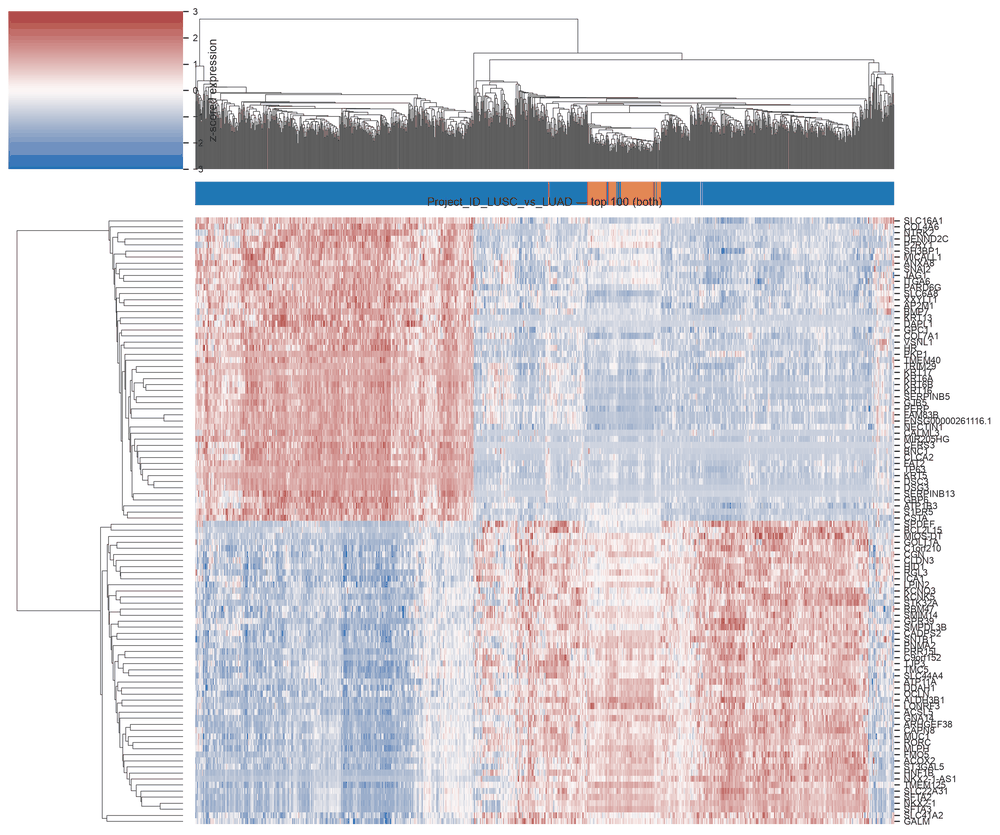

In [38]:
## 12.2. Heatmap
#res.columns.tolist()
# 2) heatmap of top DE genes
bk.pl.heatmap_de(
    adata,
    contrast="Project_ID_LUSC_vs_LUAD",
    groupby="Project_ID",
    groups=["LUSC", "LUAD"],
    layer="log1p_cpm",
    top_n=100,
    mode="both",
    col_colors=["sample_type"],
    figsize=(12, 10),
    save=FIGURES + "clustermap.png",
)


In [39]:
df_gsea.head(3)

,comparison,term,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,Project_ID_LUSC_vs_LUAD,0,prerank,MSigDB_Hallmark_2020__Epithelial Mesenchymal T...,0.730049,3.639744,0.0,0.0,0.0,129/200,10.18%,COL3A1;POSTN;SPARC;COL1A2;COL1A1;SFRP1;DCN;COL...
1,Project_ID_LUSC_vs_LUAD,1,prerank,MSigDB_Hallmark_2020__Allograft Rejection,0.708302,3.471864,0.0,0.0,0.0,115/198,10.37%,CXCL13;CCL19;SRGN;HLA-DRA;B2M;THY1;MMP9;CCL5;I...
2,Project_ID_LUSC_vs_LUAD,2,prerank,MSigDB_Hallmark_2020__Interferon Gamma Response,0.641578,3.261177,0.0,0.0,0.0,119/197,19.01%,VCAM1;CSF2RB;C1S;B2M;PDE4B;C1R;CXCL10;TNFAIP6;...


In [40]:
pre_res.res2d.head(3)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,MSigDB_Hallmark_2020__Epithelial Mesenchymal T...,0.730049,3.639744,0.0,0.0,0.0,129/200,10.18%,COL3A1;POSTN;SPARC;COL1A2;COL1A1;SFRP1;DCN;COL...
1,prerank,MSigDB_Hallmark_2020__Allograft Rejection,0.708302,3.471864,0.0,0.0,0.0,115/198,10.37%,CXCL13;CCL19;SRGN;HLA-DRA;B2M;THY1;MMP9;CCL5;I...
2,prerank,MSigDB_Hallmark_2020__Interferon Gamma Response,0.641578,3.261177,0.0,0.0,0.0,119/197,19.01%,VCAM1;CSF2RB;C1S;B2M;PDE4B;C1R;CXCL10;TNFAIP6;...


In [41]:
terms = pre_res.res2d.Term
terms

0     MSigDB_Hallmark_2020__Epithelial Mesenchymal T...
1             MSigDB_Hallmark_2020__Allograft Rejection
2       MSigDB_Hallmark_2020__Interferon Gamma Response
3       MSigDB_Hallmark_2020__Interferon Alpha Response
4                  MSigDB_Hallmark_2020__Myc Targets V1
5     MSigDB_Hallmark_2020__TNF-alpha Signaling via ...
6           MSigDB_Hallmark_2020__Inflammatory Response
7        MSigDB_Hallmark_2020__IL-6/JAK/STAT3 Signaling
8                 MSigDB_Hallmark_2020__Apical Junction
9             MSigDB_Hallmark_2020__Pancreas Beta Cells
10                     MSigDB_Hallmark_2020__Complement
11                      MSigDB_Hallmark_2020__Apoptosis
12           MSigDB_Hallmark_2020__IL-2/STAT5 Signaling
13              MSigDB_Hallmark_2020__KRAS Signaling Up
14                MSigDB_Hallmark_2020__G2-M Checkpoint
15               MSigDB_Hallmark_2020__mTORC1 Signaling
16                    MSigDB_Hallmark_2020__E2F Targets
17                 MSigDB_Hallmark_2020__UV Resp

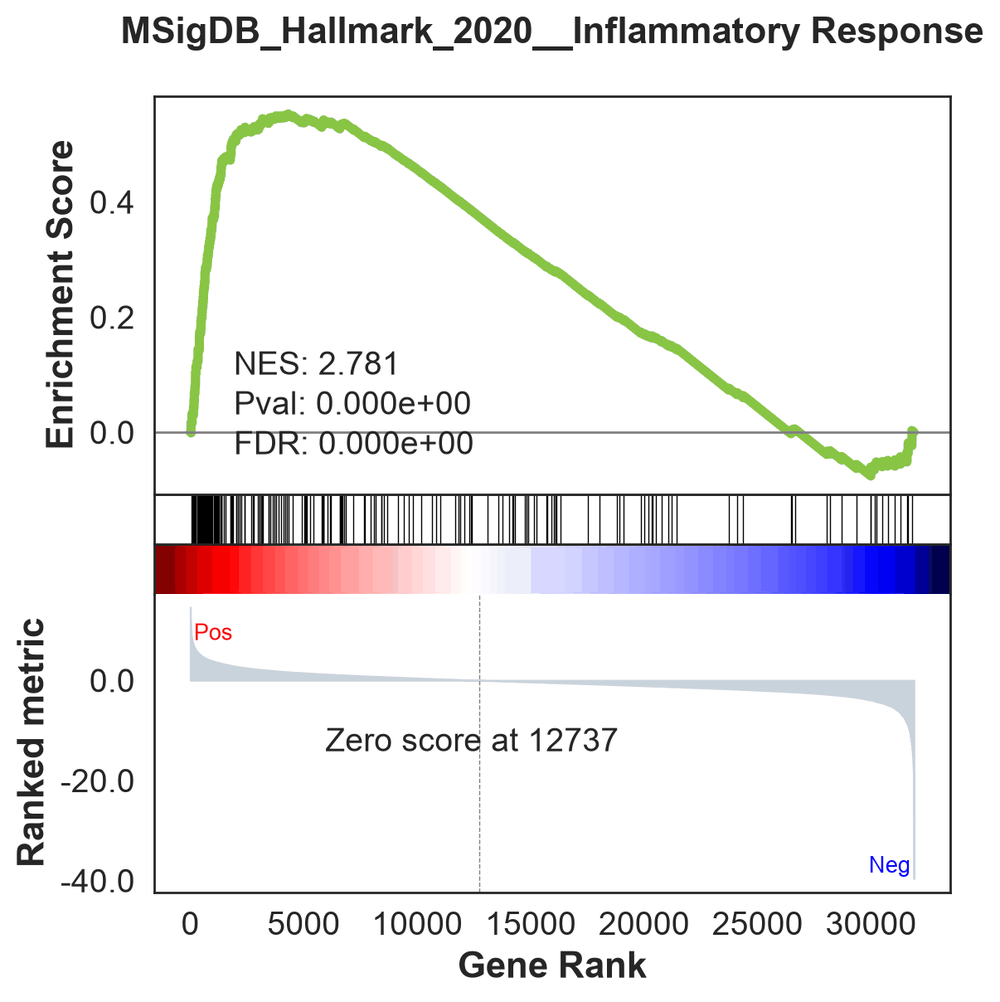

In [42]:
ax = pre_res.plot(terms=terms[6], figsize=(6, 6),) # v1.0.5

In [43]:
# plot to file
gseaplot(rank_metric=pre_res.ranking, term=terms[0], 
         ofname=FIGURES + 'your.plot.png', **pre_res.results[terms[0]])

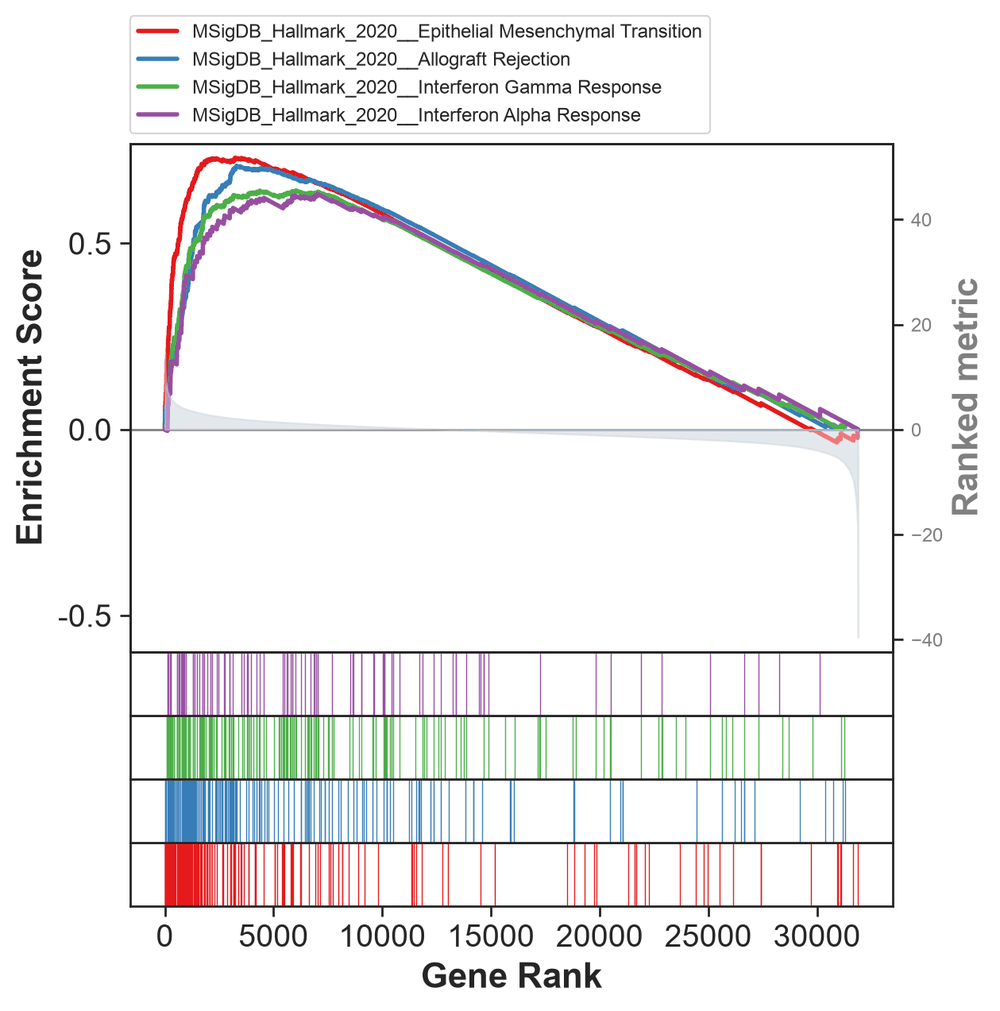

In [44]:
axs = pre_res.plot(terms=terms[0:4],
                   #legend_kws={'loc': (1.2, 0)}, # set the legend loc
                   show_ranking=True, # whether to show the second yaxis
                   figsize=(6,6)
                  )
# or use this to have more control on the plot
# from gseapy import gseaplot2
# terms = pre_res.res2d.Term[1:5]
# hits = [pre_res.results[t]['hits'] for t in terms]
# runes = [pre_res.results[t]['RES'] for t in terms]
# fig = gseaplot2(terms=terms, ress=runes, hits=hits,
#               rank_metric=gs_res.ranking,              # rank_metric=pre_res.ranking
#               legend_kws={'loc': (1.2, 0)},            # set the legend loc
#               figsize=(4,5))   

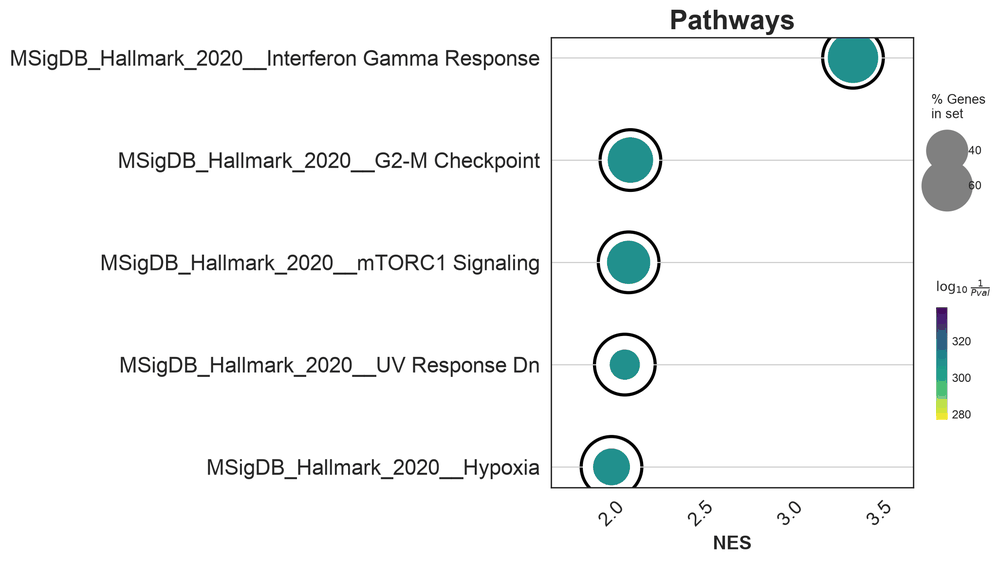

In [45]:
# categorical scatterplot
ax = gspy.dotplot(pre_res.res2d,
              column="NOM p-val",
              x='Gene_set', # set x axis, so you could do a multi-sample/library comparsion
              size=10,
              top_term=5,
              figsize=(6,6),
              title = "Pathways",
              xticklabels_rot=45, # rotate xtick labels
              show_ring=True, # set to False to revmove outer ring
              marker='o',
             )

In [46]:
# to save your figure, make sure that ``ofname`` is not None
ax = gspy.dotplot(pre_res.res2d,
             column="NOM p-val",                             #“Adjusted P-value”, “P-value”, “NOM p-val”, “FDR q-val”
             title='TEST',
             ofname=FIGURES + "mix_E3.5_KO_vs_WT.png",                                     # save to file
             cmap=plt.cm.viridis,
             top_term=12,
             size=6,                                          # adjust dot size
             figsize=(6,5), cutoff=0.25, show_ring=False)


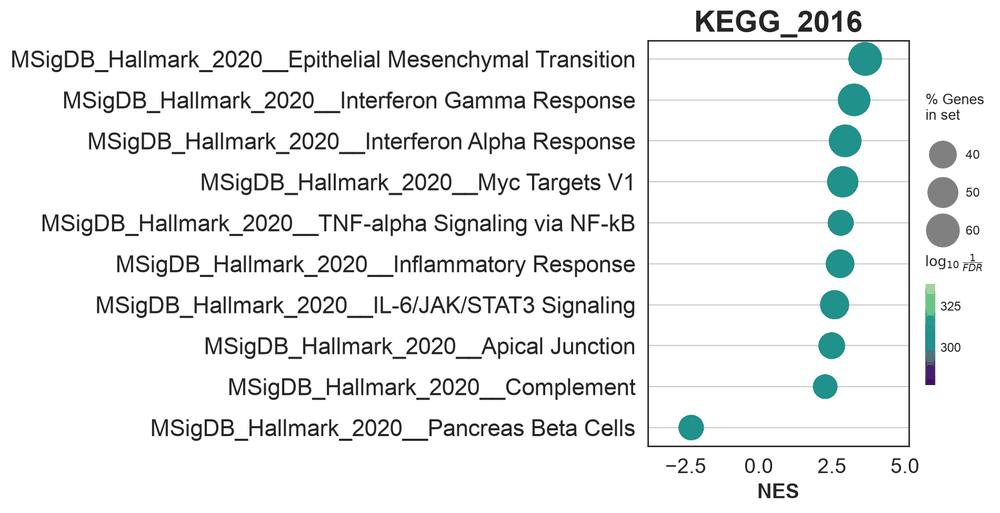

In [47]:
# to save your figure, make sure that ``ofname`` is not None
ax = gspy.dotplot(pre_res.res2d,
             column="FDR q-val",
             title='KEGG_2016',
             cmap=plt.cm.viridis,
             size=6, # adjust dot size
             figsize=(4,5), cutoff=0.25, show_ring=False)

#### Network Visualization

In [48]:
# return two dataframe
nodes, edges = enrichment_map(pre_res.res2d, cutoff = 0.25)

In [49]:
import networkx as nx
# build graph
G = nx.from_pandas_edgelist(edges,
                            source='src_idx',
                            target='targ_idx',
                            edge_attr=['jaccard_coef', 'overlap_coef', 'overlap_genes'])
G.add_nodes_from(nodes.index)   # keep pathways with no edges


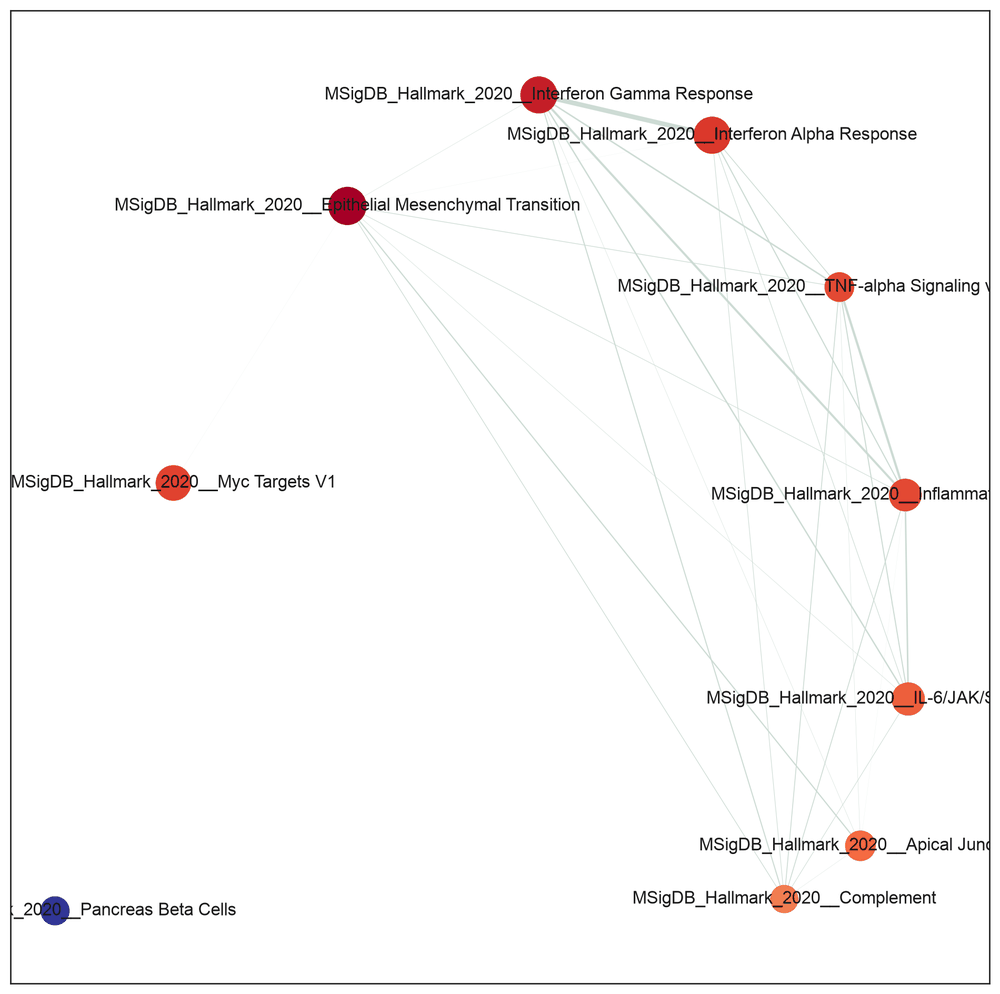

In [50]:
fig, ax = plt.subplots(figsize=(12, 12))

order = list(nodes.index)                     # same order for nodes, colours and sizes
pos = nx.spiral_layout(G)

nx.draw_networkx_nodes(G, pos=pos, nodelist=order, ax=ax,
                       cmap=plt.cm.RdYlBu_r,
                       node_color=nodes.loc[order, "NES"].tolist(),
                       node_size=(nodes.loc[order, "Hits_ratio"] * 1000).tolist())
nx.draw_networkx_labels(G, pos=pos, labels=nodes.Term.to_dict(), ax=ax)

weights = nx.get_edge_attributes(G, "jaccard_coef")
nx.draw_networkx_edges(G, pos=pos, edgelist=list(weights),
                       width=[w * 10 for w in weights.values()],
                       edge_color="#CDDBD4", ax=ax)
plt.show()


## 4.2. Leading edge analysis

In [51]:
i=0
genes = pre_res.res2d.Lead_genes[i].split(";")
genes[:10]

['COL3A1',
 'POSTN',
 'SPARC',
 'COL1A2',
 'COL1A1',
 'SFRP1',
 'DCN',
 'COL5A2',
 'LUM',
 'PRRX1']

#### Expression heatmap of frequent leading-edge genes

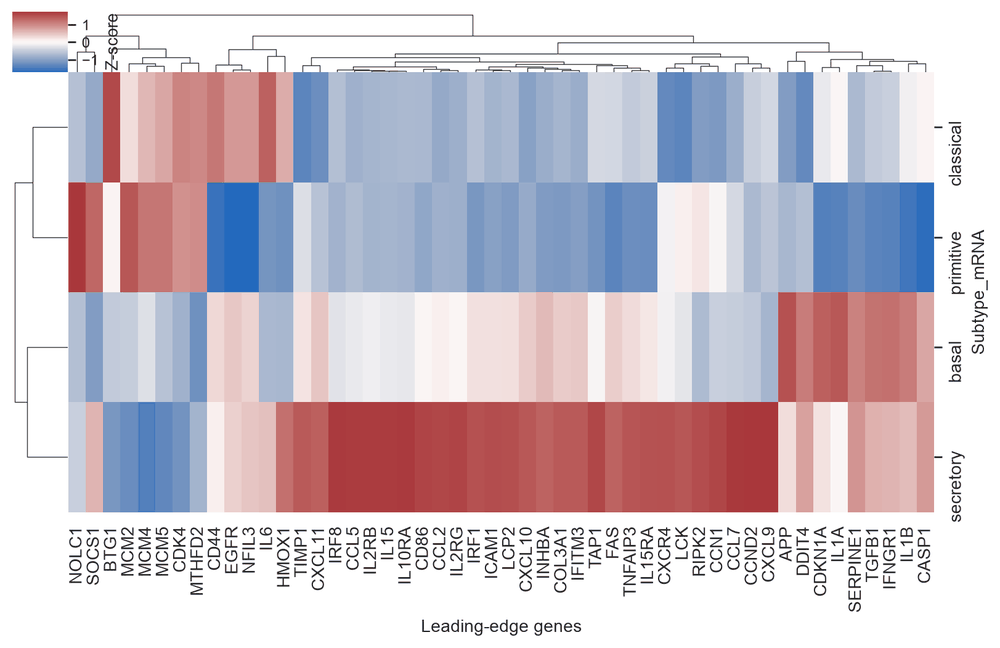

In [52]:
df_expr, g = bk.pl.gsea_leading_edge_heatmap(
    adata,
    pre_res,
    term_idx=slice(0, 30),
    use="group_mean",
    groupby="Subtype_mRNA",
    min_gene_freq=3,
    max_genes=50,
    show_labels=True,
    gene_label_fontsize=10.0,
    label_fontsize=10.0,
    title=None,
    show_title=False,
    figsize=(8,6),
    save=FIGURES + "leading_edge_expr_heatmap.png",
)

#### Jaccard similarity between pathways

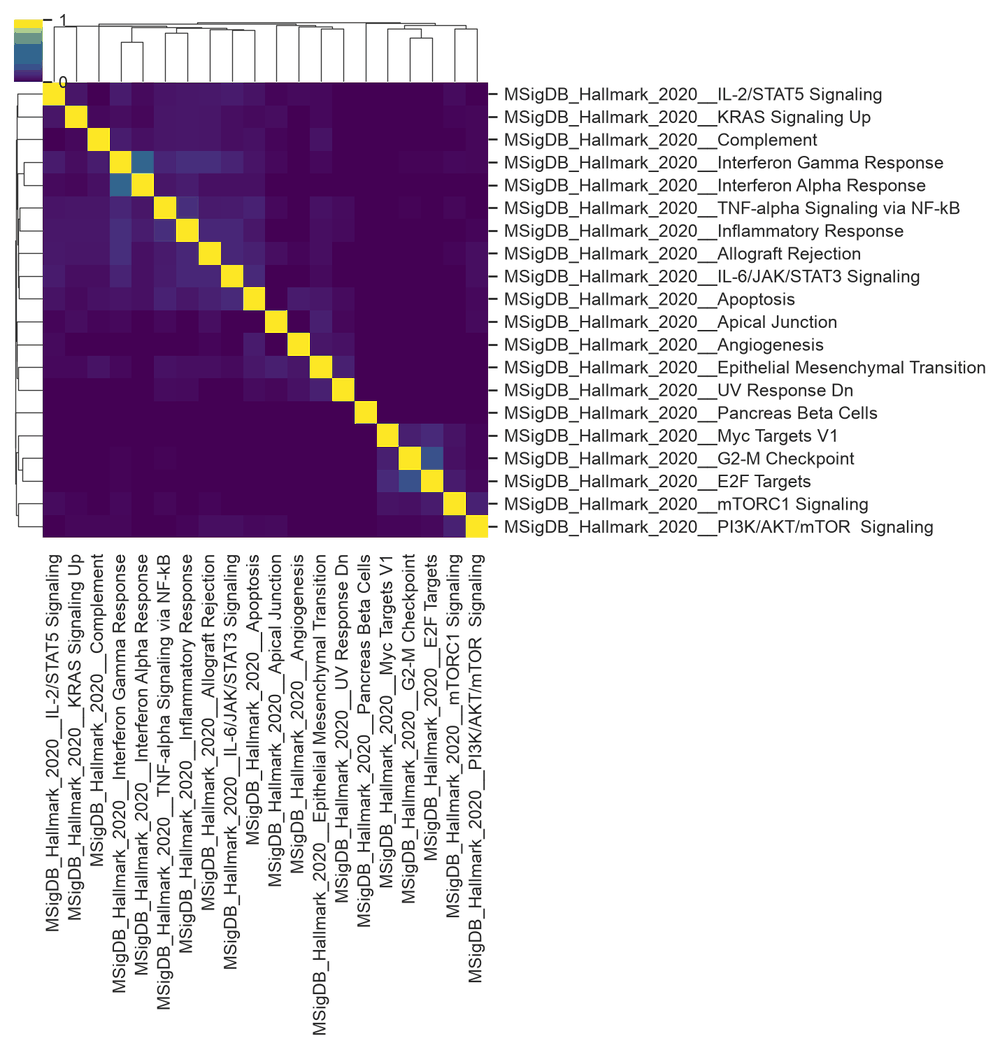

In [53]:
dfJ, g = bk.pl.leading_edge_jaccard_heatmap(
    pre_res,
    term_idx=slice(0, 20),
    min_shared_genes=2,
    row_cluster=True,
    col_cluster=True,
    show_title=False,
    #ymin=0.3,
    figsize=(7,5.5),
    save=FIGURES + "leading_edge_jaccard.png",
)

#### Overlap matrix (pathways × genes) with gene names rotated 90°

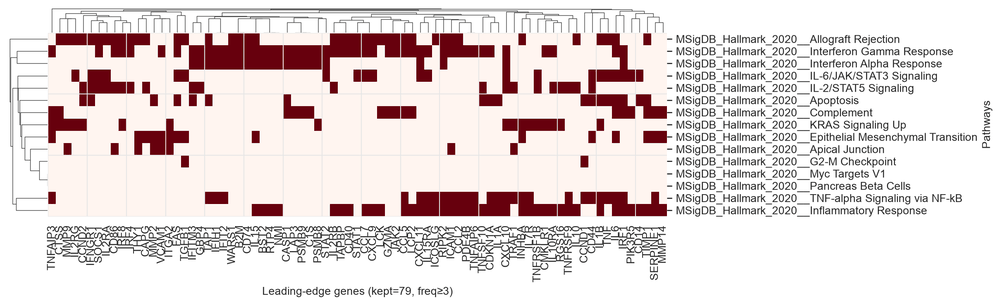

In [54]:
df_le, g = bk.pl.leading_edge_overlap_matrix(
    pre_res,
    term_idx=slice(0, 15),
    min_gene_freq=3,
    row_cluster=True,
    col_cluster=True,
    show_gene_labels=True,
    gene_label_fontsize=10,
    label_fontsize=10,
    show_title=False,
    cmap="Reds",
    figsize=(12,4),
    save=FIGURES + "leading_edge_overlap.png",
)
# plt.savefig("figs/gsea/leading_edge_overlap.png", dpi=300, bbox_inches="tight")

## 4.3. Gene sets and enrichr

Enrichr libraries for selected UP- or DOWN-regulated genes (genelists)

In [55]:
res.head(3)

,gene,log2FC,wald_z,pval,qval,dispersion,mean_norm
17136,MUC21,-1.876630,-10.535931,0.0,0.0,0.621494,2716.078762
18185,TMEM213,-2.288484,-8.458953,0.0,0.0,1.418701,248.659358
18162,LINC02418,-2.825602,-9.312903,0.0,0.0,1.749681,101.813399


In [56]:
# subset up or down regulated genes
degs_sig = res[res.qval < 0.05]
degs_up = degs_sig[degs_sig.log2FC > 1]
degs_dw = degs_sig[degs_sig.log2FC < -1]
print(degs_up.shape, "UP")
print(degs_dw.shape, "DOWN")

(846, 7) UP
(2848, 7) DOWN


In [57]:
# Over-representation analysis (Enrichr API)
enr_up = gspy.enrichr(degs_up.gene,                                # Genelist
                    gene_sets='GO_Biological_Process_2021',         # Geneset
                    outdir=None)

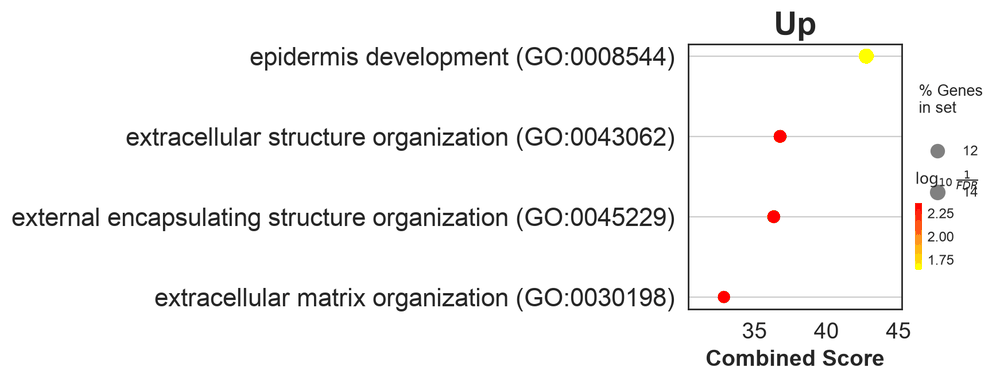

In [58]:
# dotplot
#UP
gspy.dotplot(enr_up.res2d, figsize=(3,3), title="Up", cmap = plt.cm.autumn_r)
plt.show()

In [59]:
# DOWN
enr_dw = gspy.enrichr(degs_dw.gene,
                    gene_sets='GO_Biological_Process_2021',
                    outdir=None)

enr_dw.res2d.Term = enr_dw.res2d.Term.str.split(" \(GO").str[0]

In [60]:
enr_dw.res2d

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,regulation of very-low-density lipoprotein par...,5/6,0.000309,0.477396,0,0,30.163560,2.438114e+02,APOA2;NR1H4;APOA1;APOC3;APOA5
1,GO_Biological_Process_2021,lipoprotein metabolic process,6/9,0.000473,0.477396,0,0,12.068262,9.240666e+01,NPC1L1;MTTP;APOA2;APOA1;APOA4;APOA5
2,GO_Biological_Process_2021,epoxygenase P450 pathway,9/19,0.000566,0.477396,0,0,5.434237,4.063039e+01,CYP2A7;CYP2C9;CYP2A6;CYP2C8;CYP2B6;CYP2A13;CYP...
3,GO_Biological_Process_2021,drug catabolic process,10/23,0.000652,0.477396,0,0,4.645471,3.408016e+01,CYP2A7;CYP2C9;CYP2A6;CYP2C8;CYP2B6;CYP2A13;CYP...
4,GO_Biological_Process_2021,chylomicron assembly,6/10,0.001039,0.609115,0,0,9.050669,6.217275e+01,MTTP;APOA2;APOA1;APOC3;APOA4;APOB
...,...,...,...,...,...,...,...,...,...,...
2926,GO_Biological_Process_2021,mRNA transport,1/104,0.999996,0.999996,0,0,0.058140,2.197066e-07,NXF3
2927,GO_Biological_Process_2021,mRNA export from nucleus,1/107,0.999996,0.999996,0,0,0.056484,2.132120e-07,NXF3
2928,GO_Biological_Process_2021,RNA export from nucleus,1/106,0.999996,0.999996,0,0,0.057026,2.152253e-07,NXF3
2929,GO_Biological_Process_2021,small GTPase mediated signal transduction,1/106,0.999996,0.999996,0,0,0.057026,2.152253e-07,SHC2


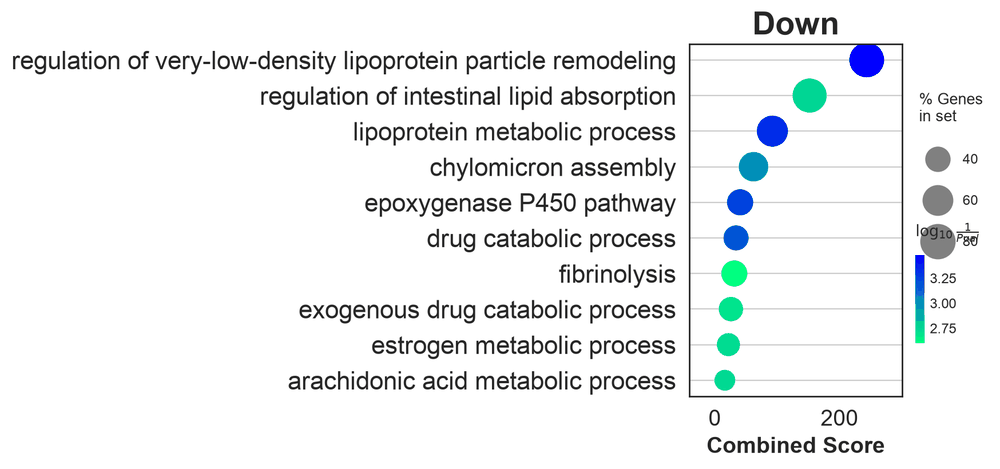

In [61]:
# GESEApy plotting functions. See parameters here: 
# https://scanpy.readthedocs.io/en/stable/generated/scanpy.pl.dotplot.html

gspy.dotplot(enr_dw.res2d,
           figsize=(3,4),
           title="Down",
           column="P-value",         #"Adjusted P-value"
           cmap = plt.cm.winter_r,
           size=5)
plt.show()

In [62]:
# concat results
enr_up.res2d['UP_DW'] = "UP"
enr_dw.res2d['UP_DW'] = "DOWN"
enr_res = pd.concat([enr_up.res2d.head(), enr_dw.res2d.head()])
enr_res

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,UP_DW
0,GO_Biological_Process_2021,extracellular matrix organization (GO:0030198),31/300,0.000004,0.004390,0,0,2.670354,32.877289,VIT;COL17A1;SPARC;NCAN;ADAMTS12;FGF2;MMP20;LOX...,UP
1,GO_Biological_Process_2021,extracellular structure organization (GO:0043062),25/216,0.000005,0.004390,0,0,3.023225,36.777285,VIT;COL17A1;SPARC;NCAN;ADAMTS12;FGF2;MMP20;ADA...,UP
2,GO_Biological_Process_2021,external encapsulating structure organization ...,25/217,0.000006,0.004390,0,0,3.007321,36.336109,VIT;COL17A1;SPARC;NCAN;ADAMTS12;FGF2;MMP20;ADA...,UP
3,GO_Biological_Process_2021,epidermis development (GO:0008544),13/83,0.000043,0.025127,0,0,4.254708,42.761032,COL17A1;WNT10A;CALML5;KRT2;KRT34;HOXB13;KRT85;...,UP
4,GO_Biological_Process_2021,chronic inflammatory response (GO:0002544),3/5,0.000707,0.258209,0,0,34.078292,247.201578,VNN1;CXCL13;TNF,UP
0,GO_Biological_Process_2021,regulation of very-low-density lipoprotein par...,5/6,0.000309,0.477396,0,0,30.163560,243.811415,APOA2;NR1H4;APOA1;APOC3;APOA5,DOWN
1,GO_Biological_Process_2021,lipoprotein metabolic process,6/9,0.000473,0.477396,0,0,12.068262,92.406655,NPC1L1;MTTP;APOA2;APOA1;APOA4;APOA5,DOWN
2,GO_Biological_Process_2021,epoxygenase P450 pathway,9/19,0.000566,0.477396,0,0,5.434237,40.630390,CYP2A7;CYP2C9;CYP2A6;CYP2C8;CYP2B6;CYP2A13;CYP...,DOWN
3,GO_Biological_Process_2021,drug catabolic process,10/23,0.000652,0.477396,0,0,4.645471,34.080164,CYP2A7;CYP2C9;CYP2A6;CYP2C8;CYP2B6;CYP2A13;CYP...,DOWN
4,GO_Biological_Process_2021,chylomicron assembly,6/10,0.001039,0.609115,0,0,9.050669,62.172749,MTTP;APOA2;APOA1;APOC3;APOA4;APOB,DOWN


In [63]:
from gseapy.scipalette import SciPalette
sci = SciPalette()
NbDr = sci.create_colormap()
# NbDr

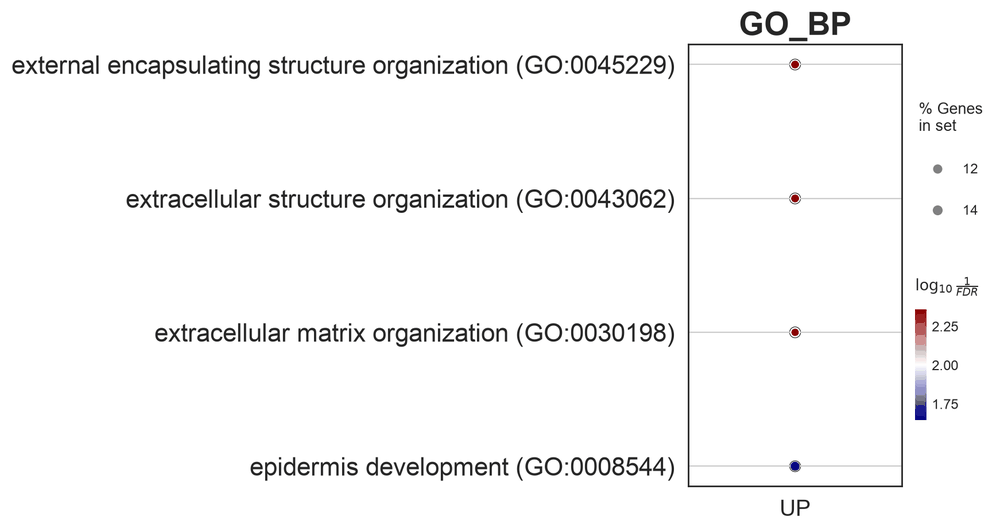

In [64]:
# display multi-datasets
ax = gspy.dotplot(enr_res,figsize=(3,5),
                x='UP_DW',
                x_order = ["DOWN", "UP"],
                title="GO_BP",
                cmap = NbDr,   # NbDr.reversed()
                size=3,
                show_ring=True)
ax.set_xlabel("")
plt.show()

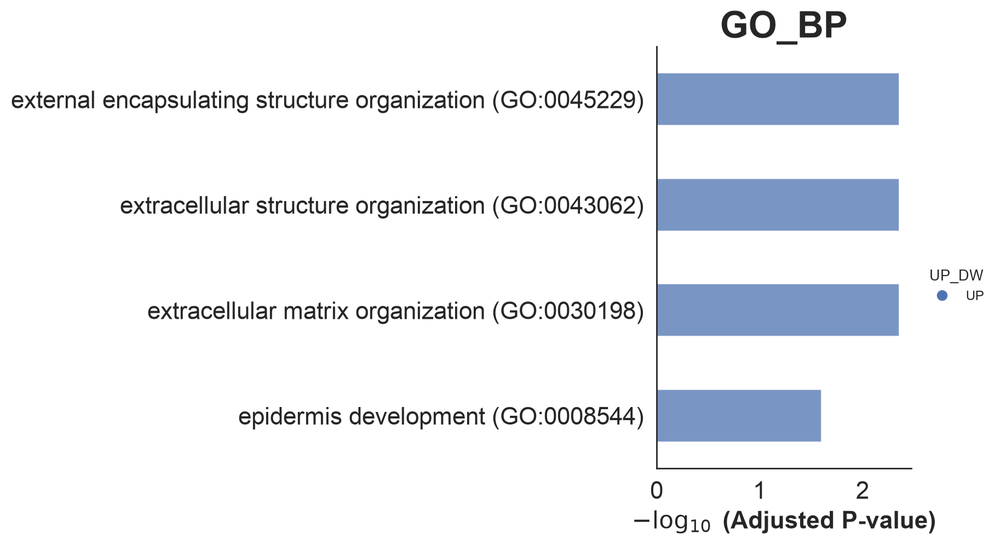

In [65]:
ax = gspy.barplot(enr_res, figsize=(3,5),
                group ='UP_DW',
                title ="GO_BP",
                color = ['b','r'])

see available libraries: https://maayanlab.cloud/Enrichr/#libraries
- TRANSFAC_and_JASPAR_PWMs
- TRRUST_Transcription_Factors_2019
- ENCODE_and_ChEA_Consensus_TFs_from_ChIP-X

In [66]:
genes_up_list = degs_up["gene"].tolist()
print(len(genes_up_list))

846


In [67]:
print(len(genes_up_list[:50]))

50


In [68]:
enr_tf = gspy.enrichr(gene_list=genes_up_list[:50],
                 gene_sets=['TRRUST_Transcription_Factors_2019'],
                 cutoff=0.1,
                 organism='h. sapiens',
                 outdir=FIGURES,
                     )

In [69]:
enr_tf

## 4.4. Series of parallel comparisons

In [70]:
dataset = adata                                    # adata, adata_lung
dataname = "TCGA"                                  # TCGA, TCGA_lung
column = "Subtype_mRNA"                                 # e,g, "Project_ID", "RB1_mut"

In [71]:
GENESETS = DATA_EXTERNAL + "gsea_2024/"

In [72]:
adata.obs.Subtype_mRNA.unique()

[NaN, 'primitive', 'classical', 'secretory', 'basal']
Categories (4, str): ['basal', 'classical', 'primitive', 'secretory']

In [73]:
# Comparison 1 ---> save to df_gsea1, pre_res1
groupA = "secretory"                                     # e.g. "LUAD", "1.0"
groupB = "basal"                                     # e.g. "LUSC", "0.0"
comparison = f"{column}_{groupA}_vs_{groupB}"
print("Comparison 01...")                   
bk.tl.de(adata, groupby=column, group=groupA, reference=groupB, method="welch_ttest", layer_expr="log1p_cpm")
res = adata.uns["de"][comparison]["results"]
df_gsea_01, pre_res_01 = bk.tl.gsea_preranked(adata, res=res, comparison=comparison, score_col="t",
    gene_sets=["hallmark"], outdir="gsea", return_pre_res=True)

# Comparison 2 ---> save to df_gsea2, , pre_res2
groupA = "secretory"                                     # e.g. "LUAD", "1.0"
groupB = "primitive"                                     # e.g. "LUSC", "0.0"
comparison = f"{column}_{groupA}_vs_{groupB}"
print("Comparison 02...")                     
bk.tl.de(adata, groupby=column, group=groupA, reference=groupB, method="welch_ttest", layer_expr="log1p_cpm")
res = adata.uns["de"][comparison]["results"]
df_gsea_02, pre_res_02 = bk.tl.gsea_preranked(adata, res=res, comparison=comparison, score_col="t",
    gene_sets=["hallmark"], outdir="gsea", return_pre_res=True)

print("Merging data from all comparisons...")
# later: concatenate across comparisons
all_gsea = pd.concat([df_gsea_01, df_gsea_02])
all_gsea.head(3)

Comparison 01...


Comparison 02...
Merging data from all comparisons...


,comparison,term,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,Subtype_mRNA_secretory_vs_basal,0,prerank,MSigDB_Hallmark_2020__Allograft Rejection,0.715471,3.231905,0.0,0.0,0.0,120/198,13.26%,CD74;CD4;HLA-DOA;CCR5;ITGB2;HLA-DRA;HLA-DQA1;H...
1,Subtype_mRNA_secretory_vs_basal,1,prerank,MSigDB_Hallmark_2020__Interferon Gamma Response,0.608667,2.779564,0.0,0.0,0.0,121/197,20.96%,CD74;SERPING1;HLA-DQA1;IL10RA;IL18BP;HLA-DMA;H...
2,Subtype_mRNA_secretory_vs_basal,2,prerank,MSigDB_Hallmark_2020__Interferon Alpha Response,0.609365,2.503562,0.0,0.0,0.0,63/97,22.84%,CD74;NUB1;TMEM140;CSF1;LAP3;GBP4;RIPK2;GMPR;UB...


In [74]:
all_gsea

,comparison,term,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,Subtype_mRNA_secretory_vs_basal,0,prerank,MSigDB_Hallmark_2020__Allograft Rejection,0.715471,3.231905,0.000000,0.000000,0.000,120/198,13.26%,CD74;CD4;HLA-DOA;CCR5;ITGB2;HLA-DRA;HLA-DQA1;H...
1,Subtype_mRNA_secretory_vs_basal,1,prerank,MSigDB_Hallmark_2020__Interferon Gamma Response,0.608667,2.779564,0.000000,0.000000,0.000,121/197,20.96%,CD74;SERPING1;HLA-DQA1;IL10RA;IL18BP;HLA-DMA;H...
2,Subtype_mRNA_secretory_vs_basal,2,prerank,MSigDB_Hallmark_2020__Interferon Alpha Response,0.609365,2.503562,0.000000,0.000000,0.000,63/97,22.84%,CD74;NUB1;TMEM140;CSF1;LAP3;GBP4;RIPK2;GMPR;UB...
3,Subtype_mRNA_secretory_vs_basal,3,prerank,MSigDB_Hallmark_2020__Complement,0.536822,2.467541,0.000000,0.000000,0.000,88/200,15.91%,ITGAM;SERPING1;DOCK10;SH2B3;SPOCK2;GNG2;C2;CTS...
4,Subtype_mRNA_secretory_vs_basal,4,prerank,MSigDB_Hallmark_2020__IL-6/JAK/STAT3 Signaling,0.603226,2.432888,0.000000,0.000000,0.000,41/87,15.20%,TNFRSF1B;ACVRL1;IL2RG;IL12RB1;A2M;LTB;PIK3R5;C...
...,...,...,...,...,...,...,...,...,...,...,...,...
45,Subtype_mRNA_secretory_vs_primitive,45,prerank,MSigDB_Hallmark_2020__PI3K/AKT/mTOR Signaling,0.203864,1.017375,0.396552,0.451456,0.981,23/104,14.57%,IL2RG;SLA;PRKCB;CAB39;MYD88;ITPR2;FASLG;DAPP1;...
46,Subtype_mRNA_secretory_vs_primitive,46,prerank,MSigDB_Hallmark_2020__Pancreas Beta Cells,0.242420,0.997665,0.444444,0.491113,0.985,6/38,9.49%,VDR;MAFB;LMO2;DPP4;PAK3;FOXO1
47,Subtype_mRNA_secretory_vs_primitive,47,prerank,MSigDB_Hallmark_2020__Notch Signaling,0.225918,0.913772,0.600683,0.711790,0.998,16/32,25.17%,CCND1;ARRB1;WNT2;HEYL;NOTCH2;DTX2;DTX4;FZD1;MA...
48,Subtype_mRNA_secretory_vs_primitive,48,prerank,MSigDB_Hallmark_2020__Protein Secretion,-0.206520,-0.896130,0.650980,0.685075,1.000,28/96,28.87%,TOM1L1;GOSR2;BNIP3;STX16;GNAS;TPD52;AP2M1;NAPG...


In [75]:
savename = dataname + "_" + column + "_comparisons.tsv"
all_gsea.to_csv(GSEA + savename, sep="\t")

## 4.5. Pathway bubble plot

In [76]:
# use all_gsea above 
#df_gsea = all_gsea.copy()
#or load a previously saved file
df_gsea = pd.read_csv(GSEA + savename, sep="\t")
df_gsea.head(3)

,Unnamed: 0,comparison,term,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,0,Subtype_mRNA_secretory_vs_basal,0,prerank,MSigDB_Hallmark_2020__Allograft Rejection,0.715471,3.231905,0.0,0.0,0.0,120/198,13.26%,CD74;CD4;HLA-DOA;CCR5;ITGB2;HLA-DRA;HLA-DQA1;H...
1,1,Subtype_mRNA_secretory_vs_basal,1,prerank,MSigDB_Hallmark_2020__Interferon Gamma Response,0.608667,2.779564,0.0,0.0,0.0,121/197,20.96%,CD74;SERPING1;HLA-DQA1;IL10RA;IL18BP;HLA-DMA;H...
2,2,Subtype_mRNA_secretory_vs_basal,2,prerank,MSigDB_Hallmark_2020__Interferon Alpha Response,0.609365,2.503562,0.0,0.0,0.0,63/97,22.84%,CD74;NUB1;TMEM140;CSF1;LAP3;GBP4;RIPK2;GMPR;UB...


In [77]:
# define pathways to represent
pathways = {
    "Immune": [
        "MSigDB_Hallmark_2020__IL-6/JAK/STAT3 Signaling",
        "MSigDB_Hallmark_2020__Interferon Alpha Response",
        "MSigDB_Hallmark_2020__Inflammatory Response",
        "MSigDB_Hallmark_2020__Interferon Gamma Response",
        "MSigDB_Hallmark_2020__Allograft Rejection",
    ],
    "Metabolism": [
        "MSigDB_Hallmark_2020__Oxidative Phosphorylation",
        "MSigDB_Hallmark_2020__Estrogen Response Early",
        "MSigDB_Hallmark_2020__Pancreas Beta Cells",
    ],
    "Cell Cycle": [
        "MSigDB_Hallmark_2020__G2-M Checkpoint",
        "MSigDB_Hallmark_2020__E2F Targets",
        "MSigDB_Hallmark_2020__Myc Targets V1",
        "MSigDB_Hallmark_2020__Myc Targets V2",
    ]
}

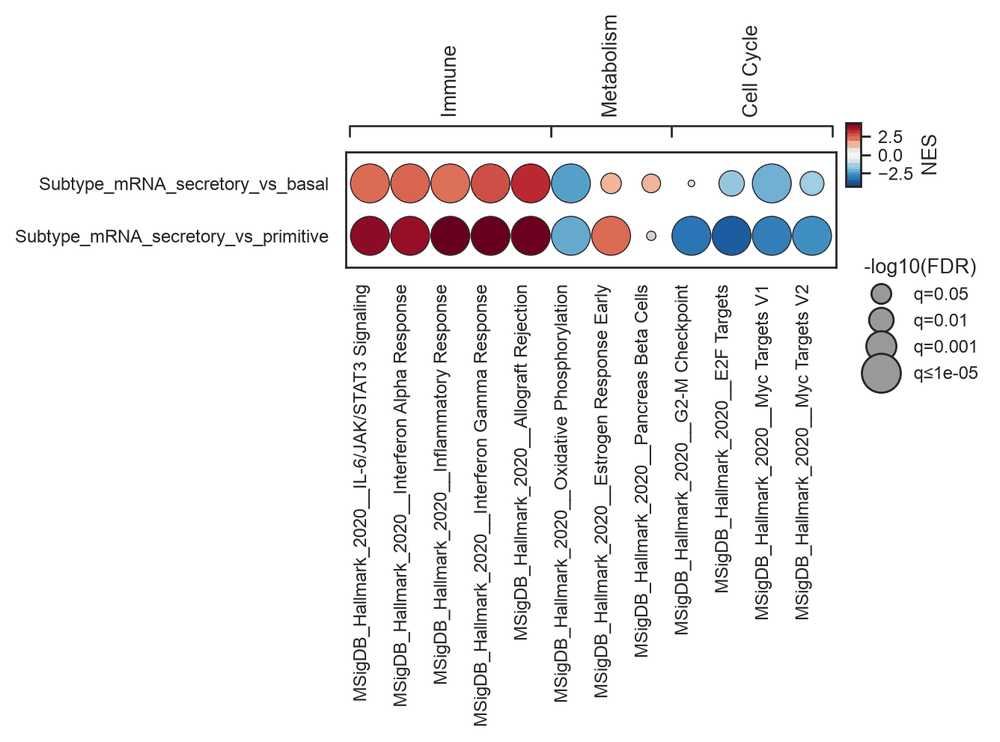

(<Figure size 1000x200 with 2 Axes>, <Axes: >)

In [78]:
bk.pl.gsea_bubbleplot(
    all_gsea,   
    pathways=pathways,
    fdr_floor=1e-5,             # <- YOU choose the floor
    size_clip_quantile=0.98,    # <- cap extremes so others don’t shrink
    dot_linewidth=0.5,
    row_height=0.1,          # tighter
    col_width=0.1,            # wider columns
    figsize=(5,1),
)

## 4.6. Genesets, GO and GSEA Utilities

### 4.6.1. Rerun GSEApy from previously saved rnk file   
(res not needed) only for plotting later:

In [79]:
comparison = "Project_ID_LUSC_vs_LUAD"
rnk_path = GSEA + f"{comparison}/{comparison}.rnk.tsv"
pre_res = gspy.prerank(rnk=rnk_path, gene_sets="MSigDB_Hallmark_2020", outdir=None)


### 4.6.2. Original genesets from GSEA - MSigDB.  
https://gseapy.readthedocs.io/en/latest/gseapy_example.html 


In [80]:
from gseapy import Msigdb
msig = Msigdb()


In [81]:
msig.list_dbver()
#msig.list_category(dbver="2025.1.Hs") 

,Name,Last modified
0,6.0,2026-07-26 21:18
1,6.1,2026-07-26 21:18
2,6.2,2026-07-26 21:18
3,7.0,2026-08-12 17:29
4,7.1,2026-07-26 21:16
5,7.2,2026-07-26 21:16
6,7.3,2026-07-26 21:16
7,7.4,2026-07-26 21:16
8,7.5.1,2026-07-26 21:16
9,7.5,2026-07-26 21:16


In [82]:
h_all = msig.get_gmt(category='h.all', dbver="2025.1.Hs")    # HALLMARKS
h_c2_all = msig.get_gmt(category='2.cp.reactome', dbver="2025.1.Hs")

In [83]:
print(h_all['HALLMARK_WNT_BETA_CATENIN_SIGNALING'])

['ADAM17', 'AXIN1', 'AXIN2', 'CCND2', 'CSNK1E', 'CTNNB1', 'CUL1', 'DKK1', 'DKK4', 'DLL1', 'DVL2', 'FRAT1', 'FZD1', 'FZD8', 'GNAI1', 'HDAC11', 'HDAC2', 'HDAC5', 'HEY1', 'HEY2', 'JAG1', 'JAG2', 'KAT2A', 'LEF1', 'MAML1', 'MYC', 'NCOR2', 'NCSTN', 'NKD1', 'NOTCH1', 'NOTCH4', 'NUMB', 'PPARD', 'PSEN2', 'PTCH1', 'RBPJ', 'SKP2', 'TCF7', 'TP53', 'WNT1', 'WNT5B', 'WNT6']


### 4.6.3. Enrichr datasets

The authoritative list is the Enrichr dataset Statistics endpoint. To discover exact names installed in your environment:

In [84]:
bk.tl.list_enrichr_libraries()[:50]

['ARCHS4_Cell-lines',
 'ARCHS4_IDG_Coexp',
 'ARCHS4_Kinases_Coexp',
 'ARCHS4_TFs_Coexp',
 'ARCHS4_Tissues',
 'Achilles_fitness_decrease',
 'Achilles_fitness_increase',
 'Aging_Perturbations_from_GEO_down',
 'Aging_Perturbations_from_GEO_up',
 'Allen_Brain_Atlas_10x_scRNA_2021',
 'Allen_Brain_Atlas_down',
 'Allen_Brain_Atlas_up',
 'Azimuth_2023',
 'Azimuth_Cell_Types_2021',
 'BioCarta_2013',
 'BioCarta_2015',
 'BioCarta_2016',
 'BioPlanet_2019',
 'BioPlex_2017',
 'CCLE_Proteomics_2020',
 'CM4AI_U2OS_Protein_Localization_Assemblies',
 'COMPARTMENTS_Curated_2025',
 'COMPARTMENTS_Experimental_2025',
 'CORUM',
 'COVID-19_Related_Gene_Sets',
 'COVID-19_Related_Gene_Sets_2021',
 'Cancer_Cell_Line_Encyclopedia',
 'Carcinogenome',
 'CellMarker_2024',
 'CellMarker_Augmented_2021',
 'ChEA_2013',
 'ChEA_2015',
 'ChEA_2016',
 'ChEA_2022',
 'Chromosome_Location',
 'Chromosome_Location_hg19',
 'ClinVar_2019',
 'ClinVar_2025',
 'DGIdb_Drug_Targets_2024',
 'DSigDB',
 'Data_Acquisition_Method_Most_Popul

# 5. Metaprograms and Tumor Heterogeneity
<a id="mp"></a>

## 5.1. Calculate and integrate metaprogram scores

Load the published MPs (no refitting):
- Gavish et al. *Nature* volume 618, pages598–606 (2023): https://www.nature.com/articles/s41586-023-06130-4
- NP gene tables in: https://www.weizmann.ac.il/sites/3CA/search-genes  

In [85]:
mp_dict = bk.tl.read_metaprograms_xlsx(
    DATA + "mp/meta_programs_2025-01-29.xlsx",
    sheet_name="Malignant",
    min_genes=10
)
len(mp_dict), list(mp_dict)[:5]

(67,
 ['MP1 Cell Cycle - G2/M',
  'MP2 Cell Cycle - G1/S',
  'MP3 Cell Cylce HMG-rich',
  'MP4 Chromatin',
  'MP5 Cell cycle single-nucleus'])

Score MPs per sample (bulk)

In [86]:
df_mp_scores, df_mp_info = bk.tl.score_metaprograms(
    adata,
    mp_dict,
    layer="log1p_cpm",
    zscore_genes=True,
    min_genes_found=8,
    prefix="MP_",
    obsm_key="X_mp",
    add_obs=True,
)
df_mp_info.head(10)

,mp,n_genes_listed,n_genes_found,genes_found,kept,reason
0,MP9 Stress 2,50,50,"[HSPH1, HSPA1A, CACYBP, CHORDC1, DNAJA1, DNAJB...",True,
1,MP10 Proteasomal degradation,50,50,"[CCT5, CCT7, CCT8, MDH1, PRMT1, PSMC4, SSB, PS...",True,
2,MP12 Protein maturation,50,50,"[HSPA5, LGALS3BP, PDIA3, GRN, PDIA6, TMEM59, A...",True,
3,MP16 EMT-II,50,50,"[LAMC2, LAMB3, KRT17, LAMA3, LGALS1, MT2A, PME...",True,
4,MP17 EMT-III,50,50,"[S100A6, ANXA2, LGALS1, S100A10, ANXA1, EMP3, ...",True,
5,MP20 EMT-VI,50,50,"[AGRN, FLNB, ITGA3, PLEC, CLSTN1, HSPG2, ITGB4...",True,
6,MP24 Interferon/MHC-II (III),50,50,"[LGALS3BP, RBP1, AP1S2, CD74, CD9, CHL1, CLU, ...",True,
7,MP26 Epithelial Senescence (HNSCC),50,50,"[KRT15, GPNMB, NUPR1, S100A2, TACSTD2, ALDH3A1...",True,
8,MP28 NRF2 targets,50,50,"[AKR1C1, AKR1C2, AKR1C3, CBR1, G6PD, PTGR1, AK...",True,
9,MP33 Secreted I,50,50,"[CXCL8, CXCL2, KDM6B, AREG, CXCL1, CXCL3, TNFR...",True,


In [87]:
adata.obs.head(3)

,Sample_ID,Patient_ID,Project_ID,gender,race,ajcc_pathologic_tumor_stage,histological_type,initial_pathologic_dx_year,birth_days_to,vital_status,...,MP_MP58_Metal_response,MP_MP59_PDAC_related_1,MP_MP60_PDAC_related_2,MP_MP61_PDAC_related_3,MP_MP62_PDAC_related_4,MP_MP63_PDAC_related_5,MP_MP64_Adherens,MP_MP65_Cholesterol_Homeostasis,MP_MP66_Unassigned_1,MP_MP67_Unassigned_2
TCGA-97-7938-01A,TCGA-97-7938-01,TCGA-97-7938,LUAD,FEMALE,WHITE,Stage IA,Lung Adenocarcinoma,2011.0,-27980.0,Dead,...,0.127409,0.147179,0.273310,0.391597,0.144484,0.421984,0.136568,-0.016691,0.791817,-0.191956
TCGA-55-7574-01A,TCGA-55-7574-01,TCGA-55-7574,LUAD,FEMALE,WHITE,Stage IB,Lung Adenocarcinoma,2011.0,-23703.0,Dead,...,0.427739,-0.083094,-0.008381,-0.000947,0.247556,0.459718,-0.161133,-0.350262,0.470536,0.451702
TCGA-05-4250-01A,TCGA-05-4250-01,TCGA-05-4250,LUAD,FEMALE,NaN,Stage IIIA,Lung Adenocarcinoma,2007.0,-29068.0,Dead,...,0.687224,0.412236,0.844336,0.051139,0.329827,0.219485,-0.020767,-0.246890,-0.080935,-0.089859


QC / sanity checks

- check how many genes found per MP
- check score distributions
- check correlation among MPs (some will correlate strongly)

In [88]:
# genes found distribution
df_mp_info[df_mp_info["kept"]][["mp","n_genes_found"]].describe()

,n_genes_found
count,67.000000
mean,47.641791
std,2.520831
min,38.000000
25%,47.000000
50%,48.000000
75%,49.500000
max,50.000000


In [89]:
# MP score correlation
mp_corr = df_mp_scores.corr()
mp_corr.head(3)

,MP1 Cell Cycle - G2/M,MP2 Cell Cycle - G1/S,MP3 Cell Cylce HMG-rich,MP4 Chromatin,MP5 Cell cycle single-nucleus,MP6 Stress 1,MP7 Hypoxia,MP8 Stress (in vitro),MP9 Stress 2,MP10 Proteasomal degradation,...,MP58 Metal-response,MP59 PDAC-related 1,MP60 PDAC-related 2,MP61 PDAC-related 3,MP62 PDAC-related 4,MP63 PDAC-related 5,MP64 Adherens,MP65 Cholesterol Homeostasis,MP66 Unassigned 1,MP67 Unassigned 2
MP1 Cell Cycle - G2/M,1.000000,0.968180,0.859936,0.095116,0.909532,-0.363051,0.544009,0.378108,0.669193,0.744219,...,-0.302898,-0.235957,-0.107638,-0.356388,-0.515425,-0.275944,0.330004,0.139379,-0.212291,-0.129213
MP2 Cell Cycle - G1/S,0.968180,1.000000,0.843408,0.177588,0.943622,-0.337385,0.527316,0.383944,0.678361,0.726882,...,-0.301251,-0.268159,-0.117695,-0.357555,-0.494273,-0.217688,0.378765,0.175667,-0.141180,-0.044026
MP3 Cell Cylce HMG-rich,0.859936,0.843408,1.000000,-0.161108,0.702719,-0.277748,0.507525,0.539742,0.703886,0.930206,...,-0.132250,-0.186017,-0.126289,-0.343192,-0.538092,-0.437043,0.136088,0.236122,-0.429792,-0.177019


Heterogeneity per tumor group + downstream association

In [90]:
df_het = bk.tl.metaprogram_heterogeneity(
    adata,
    groupby="Project_ID",
    stat="sd",
)

In [91]:
df_het.head(3)

,group,mp,mean,heterogeneity_sd,n
0,LUAD,MP1,-0.355805,0.829881,567
1,LUAD,MP2,-0.348739,0.754782,567
2,LUAD,MP3,-0.246587,0.609674,567


In [92]:
# Example: for each project, overall MP heterogeneity summary
df_project_summary = (
    df_het.groupby("group")["heterogeneity_sd"]
    .agg(["mean","median","max"])
    .reset_index()
)
df_project_summary.head()

,group,mean,median,max
0,LUAD,0.447959,0.416286,0.829881
1,LUSC,0.449993,0.405828,0.781834


Then you can correlate:  
- MP scores (sample-level) with therapy response / NR@6m
- MP heterogeneity (group-level) with prognosis metrics or resistance rates

Plots

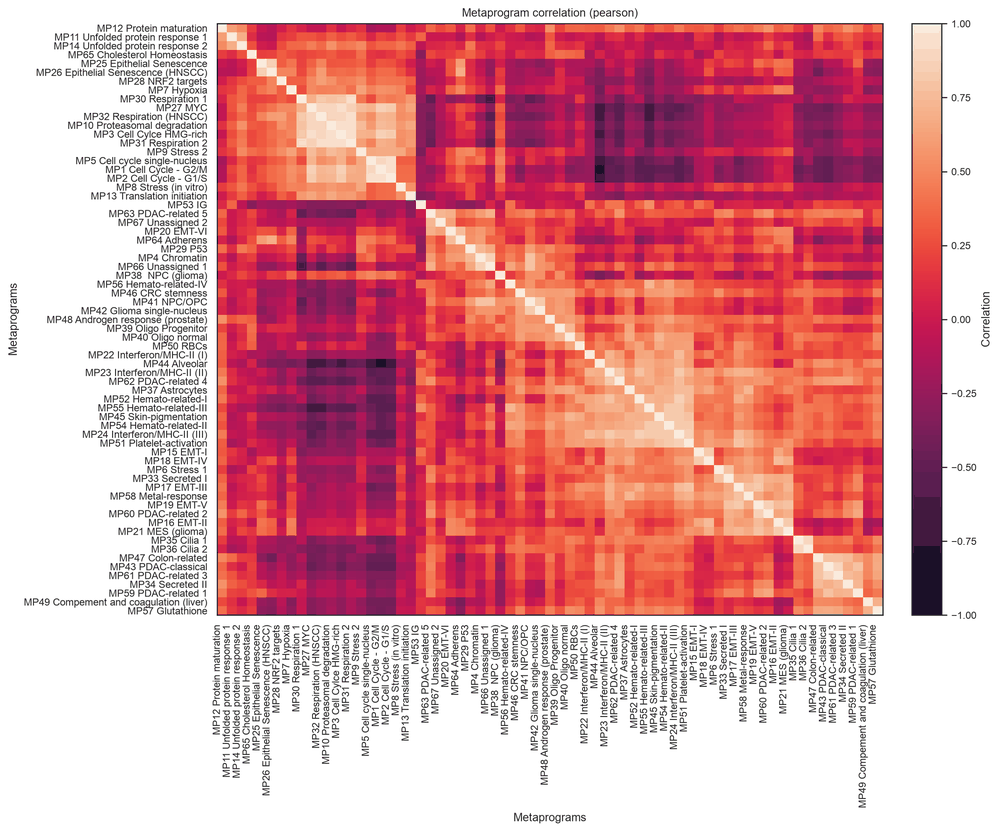

In [93]:
# 1) after you ran bk.tl.score_metaprograms(...) storing adata.obsm["X_mp"]
df_corr = bk.pl.metaprogram_corr(
    adata,
    obsm_key="X_mp",
    method="pearson",
    cluster=True,
    figsize=(12, 10),
)

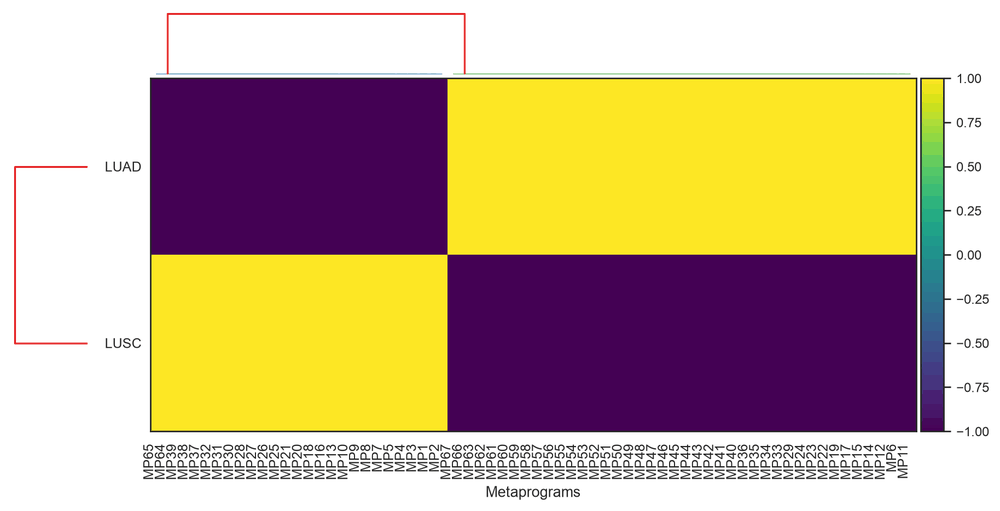

In [94]:
# 2) heatmap aggregated by tumor type
df_heat, df_group = bk.pl.metaprogram_heatmap(
    adata,
    obsm_key="X_mp",
    groupby="Project_ID",
    agg="mean",
    scale="zscore_cols",
    order_mps="cluster",
    order_groups="cluster",              # # "size", "alpha", None, "cluster"
    row_dendrogram=True,
    col_dendrogram=True,
    dendrogram_ratio=(0.1, 0.05),   # (row_dendro_width, col_dendro_height) in figure fraction-ish
    row_dendro_width=0.1,
    col_dendro_height=0.18,
    dendro_gap=0.07,
    ytick_pad=1,
    rotate_xticks=90,
    figsize=(11, 5),
)

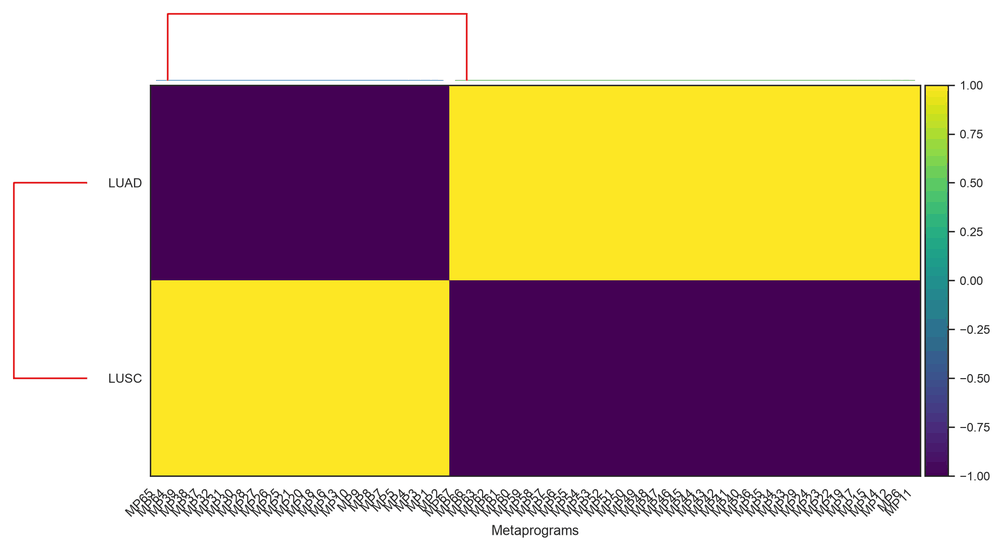

In [95]:
df_heat, df_group = bk.pl.metaprogram_heatmap(
    adata,
    groupby="Project_ID",
    order_groups="cluster",
    order_mps="cluster",
    row_dendrogram=True,
    col_dendrogram=True,
    dendrogram_ratio=(0.1, 0.05),   # (row_dendro_width, col_dendro_height) in figure fraction-ish
    row_dendro_width=0.1,
    col_dendro_height=0.18,
    dendro_gap=0.07,
    ytick_pad=1,
)

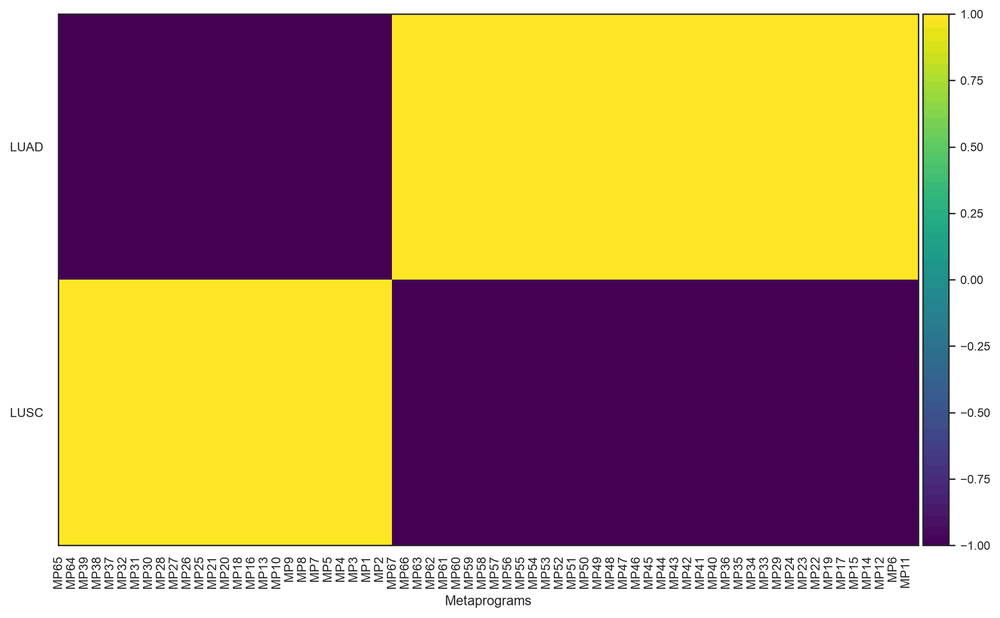

In [96]:
df_heat, df_group = bk.pl.metaprogram_heatmap(
    adata,
    groupby="Project_ID",
    order_groups="alpha",       #"cluster"
    order_mps="cluster",
    row_dendrogram=False,
    col_dendrogram=False,
    rotate_xticks=90,
    figsize=(12, 7),
)

## 11.2. Functional tumor heterogeneity and dispersion in metaprograms

In [97]:
# 1) compute per-sample metaprogram heterogeneity + dispersion
bk.tl.metaprogram_sample_metrics(
    adata,
    groupby="Project_ID",
    out_prefix="mp",
    heterogeneity="entropy",
    dispersion="mad",
    zscore_within_group=True,
)

In [98]:
# 2) compute per-group metaprogram dispersion table
bk.tl.metaprogram_dispersion_by_group(adata, groupby="Project_ID", method="mad")

,group,metaprogram,dispersion,n
0,LUAD,MP1,0.634153,567
1,LUAD,MP2,0.560798,567
2,LUAD,MP3,0.413084,567
3,LUAD,MP4,0.355899,567
4,LUAD,MP5,0.512800,567
...,...,...,...,...
129,LUSC,MP63,0.216660,541
130,LUSC,MP64,0.334987,541
131,LUSC,MP65,0.225151,541
132,LUSC,MP66,0.237131,541


In [99]:
# 3) optional: link metaprograms to NE signature score
bk.tl.metaprogram_ne_enrichment(adata, ne_signature_key="Neuroendocrine_score")

,metaprogram,rho,pval,n,qval
0,MP63,-0.454383,1.518237e-57,1108,1.017218e-55
1,MP36,-0.409040,6.201551e-46,1108,2.077519e-44
2,MP55,-0.393022,3.067218e-42,1108,6.850120e-41
3,MP67,-0.384487,2.364962e-40,1108,3.961311e-39
4,MP45,-0.381886,8.664669e-40,1108,1.161066e-38
...,...,...,...,...,...
62,MP25,-0.043911,1.440971e-01,1108,1.532461e-01
63,MP26,0.035983,2.313902e-01,1108,2.422366e-01
64,MP12,-0.033685,2.625833e-01,1108,2.706628e-01
65,MP65,0.007857,7.939008e-01,1108,8.059296e-01


In [100]:
# 4) optional: compute top-k dominance per sample
bk.tl.metaprogram_topk_contribution(adata, k=3)

,sample,rank,metaprogram,weight,score
0,TCGA-97-7938-01A,1,MP44,0.040105,1.180241
1,TCGA-97-7938-01A,2,MP6,0.039494,1.164889
2,TCGA-97-7938-01A,3,MP33,0.037942,1.124793
3,TCGA-55-7574-01A,1,MP53,0.036881,0.998020
4,TCGA-55-7574-01A,2,MP55,0.035402,0.957088
...,...,...,...,...,...
3319,TCGA-43-6647-01A,2,MP16,0.050467,1.185094
3320,TCGA-43-6647-01A,3,MP18,0.031608,0.717182
3321,TCGA-56-7730-11A,1,MP35,0.092860,2.001561
3322,TCGA-56-7730-11A,2,MP36,0.066750,1.671429


obsm["X_mp"] likely has no column names stored. Since you also have metaprograms as .obs columns (MP_MP1_... etc.), you can sync names

In [101]:
#mp_cols = [c for c in adata.obs.columns if c.startswith("MP_")]
#adata.uns["metaprogram_names"] = mp_cols

### Dispersion plots

#### Heatmap: metaprogram dispersion by tumor type
Identify which tumors show highest program variability; highlight NE-related or other MPs later.   

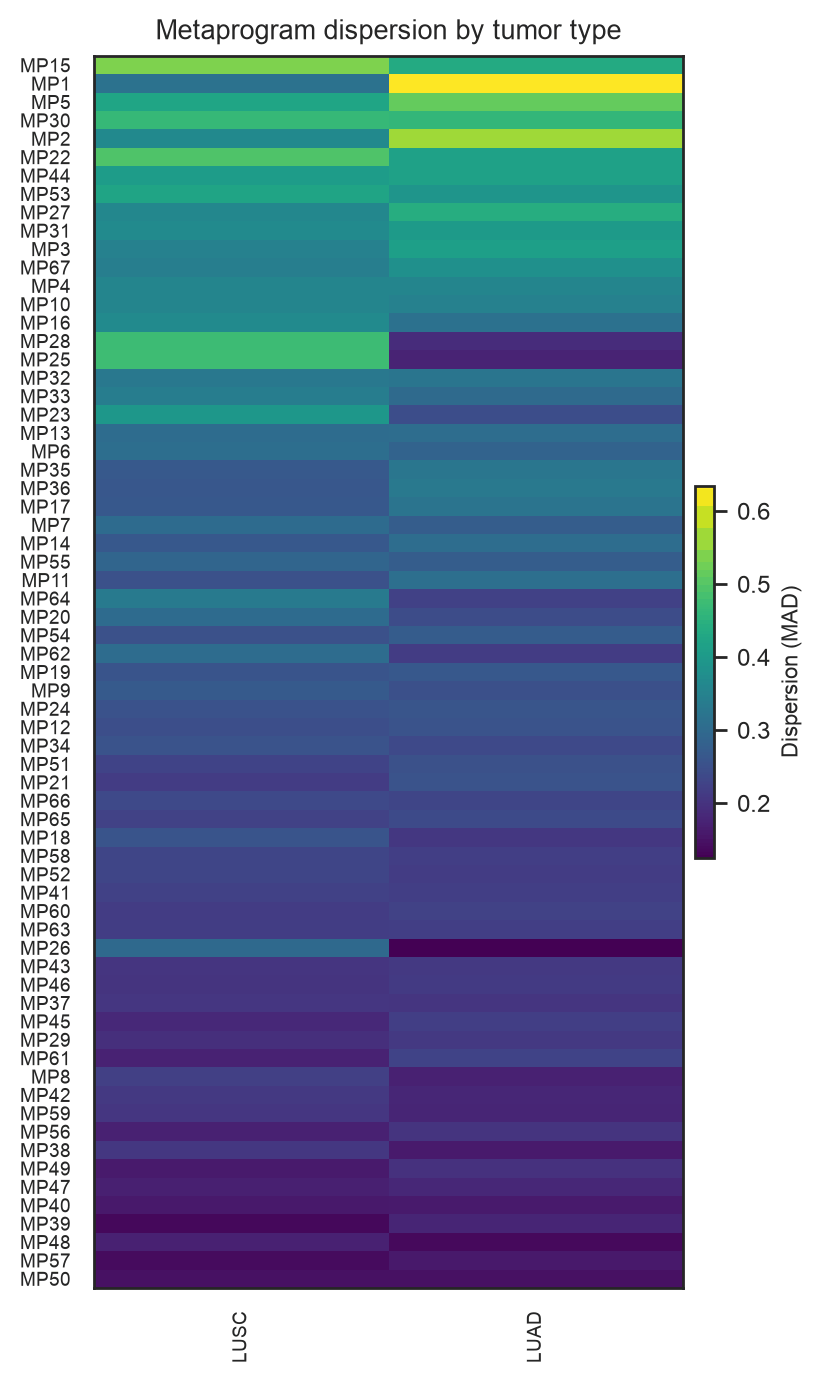

<Axes: title={'center': 'Metaprogram dispersion by tumor type'}>

In [102]:
bk.pl.metaprogram_dispersion_heatmap(adata, figsize=(4,8),
                                    save=FIGURES + "metaprogram_dispersion.png")

#### Summary: heterogeneity + dispersion by tumor type (two boxplots)

Show cohort-level differences in “program mixture” (entropy) and dispersion.

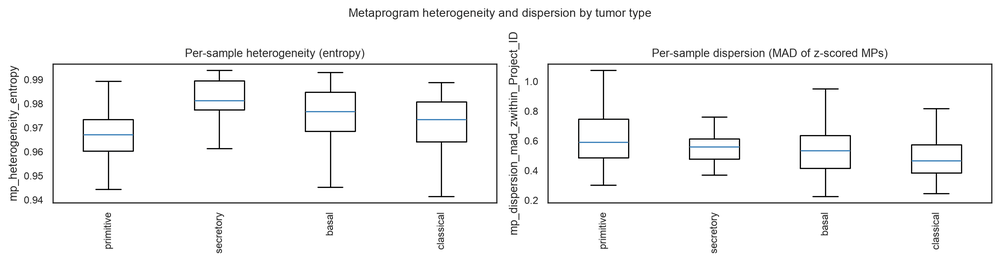

array([<Axes: title={'center': 'Per-sample heterogeneity (entropy)'}, ylabel='mp_heterogeneity_entropy'>,
       <Axes: title={'center': 'Per-sample dispersion (MAD of z-scored MPs)'}, ylabel='mp_dispersion_mad_zwithin_Project_ID'>],
      dtype=object)

In [104]:
bk.pl.metaprogram_metrics_summary(
    adata,
    groupby="Subtype_mRNA",
    heterogeneity_key="mp_heterogeneity_entropy",
    dispersion_key="mp_dispersion_mad_zwithin_Project_ID",
    save=FIGURES + "metaprogram_metrics.png",
)


#### Scatter: NE score vs metaprogram heterogeneity (or dispersion)

“NE ↔ heterogeneity” centerpiece.

#### NE vs heterogeneity entropy

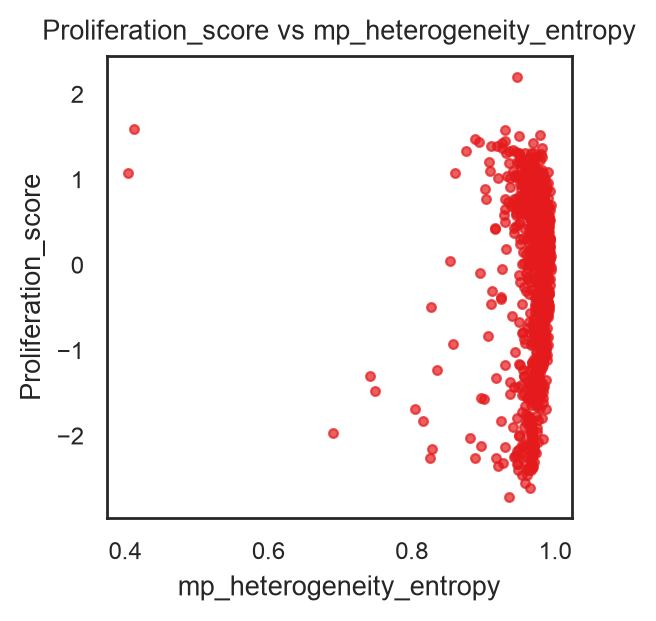

<Axes: title={'center': 'Proliferation_score vs mp_heterogeneity_entropy'}, xlabel='mp_heterogeneity_entropy', ylabel='Proliferation_score'>

In [105]:
bk.pl.metaprogram_ne_scatter(adata, ne_key="Proliferation_score", 
                             x_key="mp_heterogeneity_entropy", figsize=(3,3),
                            save= FIGURES + "metaprogram_entropy_scatter.png")

#### NE vs dispersion

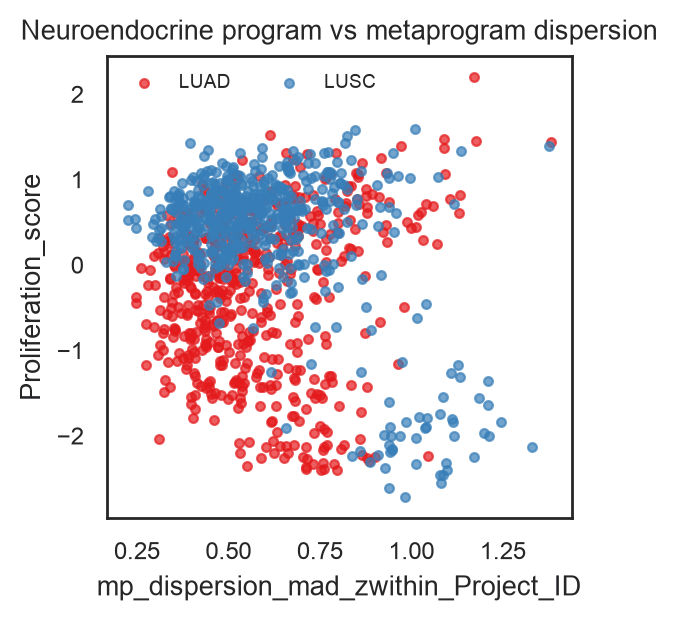

In [106]:
ax = bk.pl.metaprogram_ne_scatter(
    adata,
    ne_key="Proliferation_score",
    x_key="mp_dispersion_mad_zwithin_Project_ID",
    groupby="Project_ID",
    max_groups=10,
    title="Neuroendocrine program vs metaprogram dispersion",
    show=True,
    figsize=(3,3),
    save=FIGURES + "Fig_NE_vs_MP_dispersion.png",
)

#### Dominance: top metaprogram weight distribution by tumor type

Show whether tumors are dominated by one MP (low heterogeneity) vs distributed (high heterogeneity).  

This uses adata.uns["mp_topk"]. It plots the distribution of the rank-1 metaprogram weight per tumor type.  

In [107]:
bk.tl.metaprogram_topk_contribution(adata)

,sample,rank,metaprogram,weight,score
0,TCGA-97-7938-01A,1,MP44,0.040105,1.180241
1,TCGA-97-7938-01A,2,MP6,0.039494,1.164889
2,TCGA-97-7938-01A,3,MP33,0.037942,1.124793
3,TCGA-55-7574-01A,1,MP53,0.036881,0.998020
4,TCGA-55-7574-01A,2,MP55,0.035402,0.957088
...,...,...,...,...,...
3319,TCGA-43-6647-01A,2,MP16,0.050467,1.185094
3320,TCGA-43-6647-01A,3,MP18,0.031608,0.717182
3321,TCGA-56-7730-11A,1,MP35,0.092860,2.001561
3322,TCGA-56-7730-11A,2,MP36,0.066750,1.671429


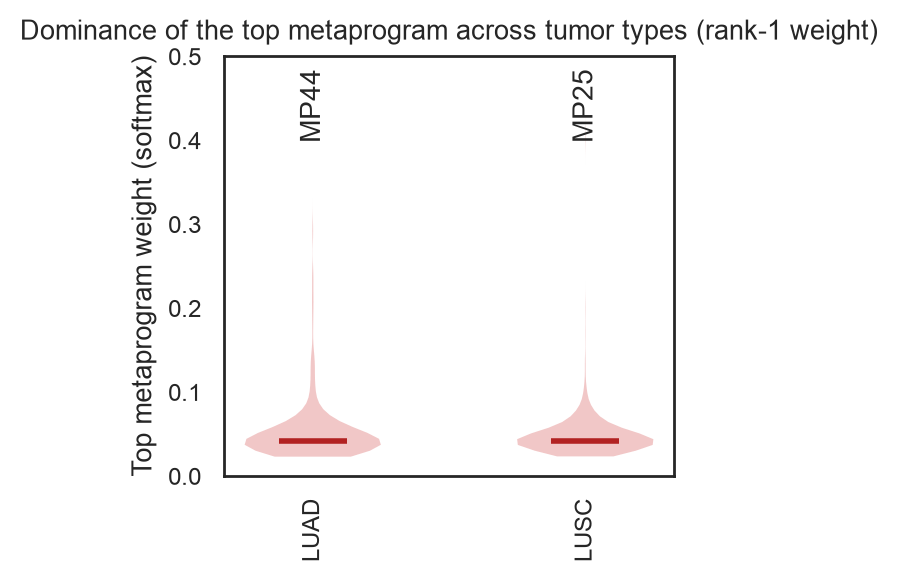

<Axes: title={'center': 'Dominance of the top metaprogram across tumor types (rank-1 weight)'}, ylabel='Top metaprogram weight (softmax)'>

In [108]:
bk.pl.metaprogram_dominance_ridgeplot_like(
    adata,
    topk_key="mp_topk",
    groupby="Project_ID",
    weight_key= "weight",
    rank=1,
    #max_groups=12,
    ylim=(0, 0.5),
    #y_text=1,                                # None
    fontsize=10,
    figsize=(3, 3),
    save=FIGURES+"Fig_MP_rank1_dominance.png",
)

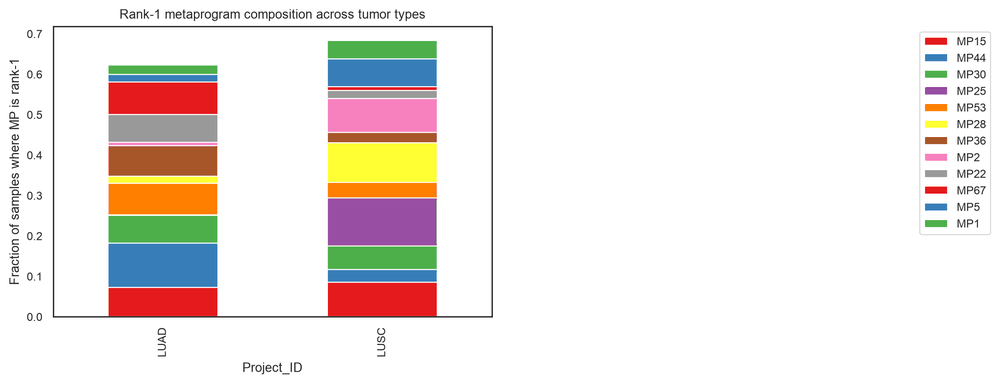

<Axes: title={'center': 'Rank-1 metaprogram composition across tumor types'}, xlabel='Project_ID', ylabel='Fraction of samples where MP is rank-1'>

In [109]:
bk.pl.metaprogram_rank1_composition_stackedbar(
    adata,
    topk_key="mp_topk",
    groupby="Project_ID",
    rank=1,
    top_groups=12,
    top_mps=12,
    figsize=(6, 4),
    legend=True,
    legend_bbox_to_anchor=(2.15, 1.0),
    legend_loc="upper right",
    rotation=90,
    title="Rank-1 metaprogram composition across tumor types",
    ylabel="Fraction of samples where MP is rank-1",
    show=True,
    save=FIGURES + "mp_stackedbar.png",
    out_key="mp_rank1_composition",
)

limiting to the top ~10–15 MPs globally keeps the figure readable. You can add a “Other” category if you want.

## 6. Survival Analysis 
<a id="survival"></a>

### 6.1. Cox univariate

heterogeneity entropy, continuous values

In [110]:
adata.obs["Neuroendocrine_score"] = pd.to_numeric(adata.obs["Neuroendocrine_score"], errors="coerce")

In [111]:
res, models = bk.tl.cox_univariate(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_keys=[
        "mp_heterogeneity_entropy",
        "mp_dispersion_mad_zwithin_Project_ID",
        "Neuroendocrine_score",
        "Proliferation_score",
    ],
    x_mode="continuous",
    strata="Project_ID",
    out_key="cox_compare_candidates",
)

`bk.pl.cox_forest_from_uns()`:  
If uns is provided, adata can be None. If uns is None, adata must be provided and contain uns_key.

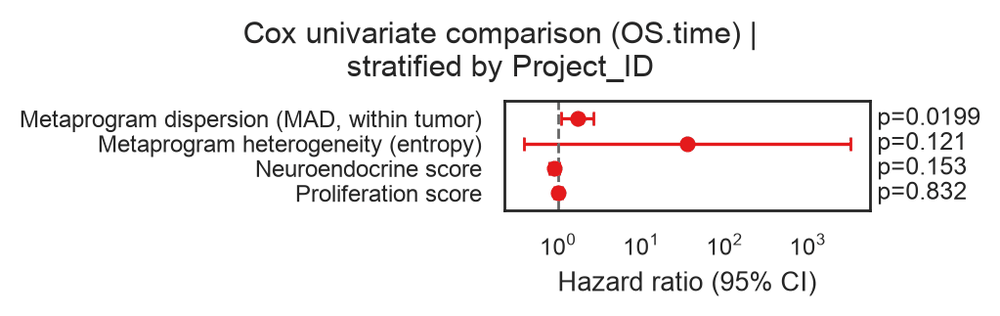

<Axes: xlabel='Hazard ratio (95% CI)'>

In [112]:
bk.pl.cox_forest_from_uns(
    adata,
    uns_key="cox_compare_candidates",
    rename={
        "mp_heterogeneity_entropy": "Metaprogram heterogeneity (entropy)",
        "mp_dispersion_mad_zwithin_Project_ID": "Metaprogram dispersion (MAD, within tumor)",
        "Neuroendocrine_score": "Neuroendocrine score",
        "Proliferation_score": "Proliferation score",
    },
    sort_by="p",
    xscale="log",
    figsize=(5,1.5),
    save=FIGURES+"Fig_CoxForest_compare_predictors.png",
)

#### Run cox per group (in Project_ID)

In [113]:
cox_by_project = bk.pl.run_cox_per_group(
    adata,
    group_col="Project_ID",
    min_n=30,
    time_key="OS.time",
    event_key="OS",
    x_keys=[
        "mp_heterogeneity_entropy",
        "mp_dispersion_mad_zwithin_Project_ID",
        "Neuroendocrine_score",
        "Proliferation_score",
    ],
    strata=None,   # or e.g. strata="sex" if present within each tumor type
)

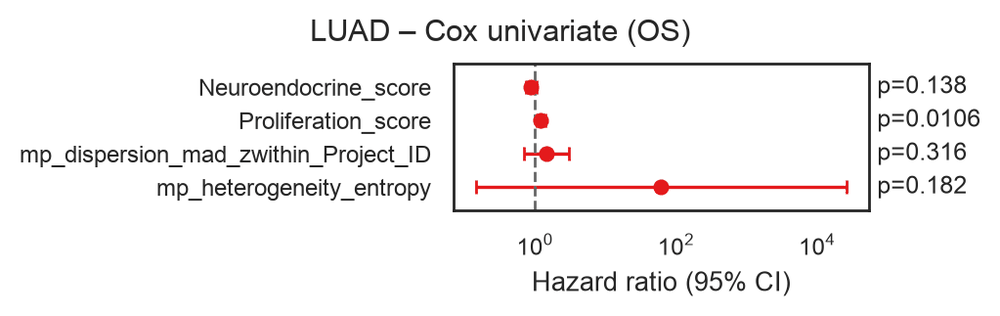

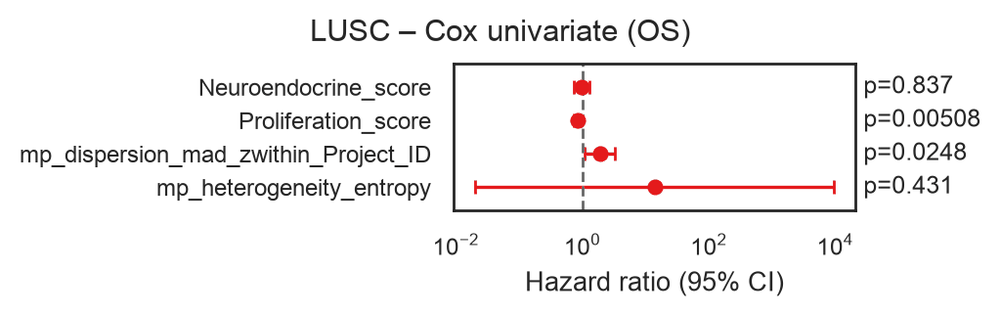

In [114]:
for pid, res in cox_by_project.items():
    bk.pl.cox_forest_from_uns(
        adata=None,
        uns=res,                     # now supported
        title=f"{pid} – Cox univariate (OS)",
        sort_by="name",
        xscale="log",
        figsize=(5, 1.5),          # or None for auto-height
        show=True,
        save=FIGURES + f"Fig_CoxForest_{pid}.png",
    )

cox_by_project

In [115]:
def summarize_one_x_across_groups(cox_by_project: dict, x_key: str) -> dict:
    rows = []
    for pid, payload in cox_by_project.items():
        summ = payload.get("summary", None)
        if summ is None:
            continue
        if not isinstance(summ, pd.DataFrame):
            summ = pd.DataFrame(summ)

        # --- handle the “tidy multi-x” format ---
        if "x_key" in summ.columns:
            sub = summ[summ["x_key"].astype(str) == str(x_key)].copy()
            if sub.shape[0] == 0:
                continue
            r = sub.iloc[0]

        # --- handle “lifelines-like” single-model summary (indexed by covariate) ---
        else:
            if summ.index.name is None and "covariate" in summ.columns:
                summ = summ.set_index("covariate")
            if str(x_key) not in summ.index.astype(str):
                continue
            r = summ.loc[str(x_key)]

        rows.append(
            dict(
                x_key=str(pid),                       # project name becomes x_key
                term=str(x_key),                      # keep original covariate name
                HR=float(r["HR"]),
                HR_lower_95=float(r["HR_lower_95"]),
                HR_upper_95=float(r["HR_upper_95"]),
                p=float(r.get("p", np.nan)),
                n_used=float(r.get("n_used", np.nan)),
                events=float(r.get("events", np.nan)),
            )
        )

    df = pd.DataFrame(rows)
    return {
        "summary": df,
        "params": {"time_key": "OS.time", "strata": None, "note": f"{x_key} across groups"},
    }

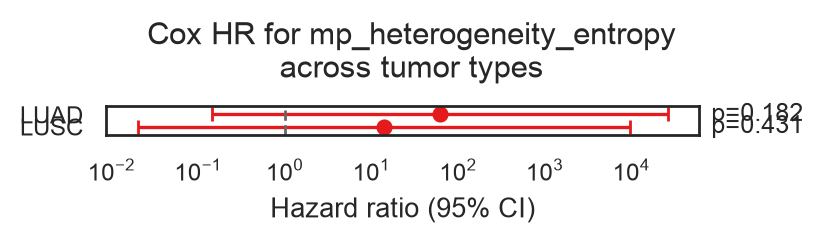

In [116]:
uns_one = summarize_one_x_across_groups(cox_by_project, "mp_heterogeneity_entropy")

ax = bk.pl.cox_forest_from_uns(
    adata=None,                 # if your updated function allows
    uns=uns_one,                # <-- pass directly
    title="Cox HR for mp_heterogeneity_entropy across tumor types",
    sort_by="HR",               # or "p" or "name"
    xscale="log",               # recommended for HR
    figsize=(4, 0.1 * len(uns_one["summary"]) + 0.9),
    show=True,
    save=FIGURES + "Fig_CoxForest_mp_heterogeneity_byProject.svg",
)

keep only projects with enough events or significant p-values

In [117]:
df = uns_one["summary"].copy()
df = df[df["events"].fillna(0) >= 20]          # example
uns_one["summary"] = df

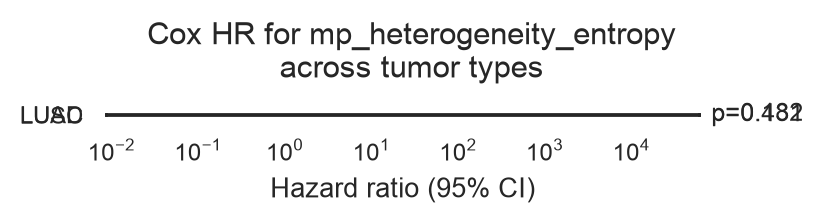

In [118]:
ax = bk.pl.cox_forest_from_uns(
    adata=None,                 # if your updated function allows
    uns=uns_one,                # <-- pass directly
    title="Cox HR for mp_heterogeneity_entropy across tumor types",
    sort_by="HR",               # or "p" or "name"
    xscale="log",               # recommended for HR
    figsize=(4, 0.1 * len(uns_one["summary"]) + 0.8),
    show=True,
    save=FIGURES +"Fig_CoxForest_mp_heterogeneity_byProject.svg",
)
ax.set_xlim(0, 3.0)
plt.show()

Binary extremes (if you prefer)

In [119]:
bk.tl.cox_univariate(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_keys=["mp_heterogeneity_entropy", "Neuroendocrine_score"],
    x_mode="binary",
    q=(0.25, 0.75),
    binning="global",
    groupby="Project_ID",
    strata="Project_ID",
    out_key="cox_compare_binary",
)


(                      x_key   term      coef        HR  HR_lower_95  \
 0  mp_heterogeneity_entropy  x_bin  0.182206  1.199862     0.918698   
 1      Neuroendocrine_score  x_bin  0.038991  1.039762     0.790241   
 
    HR_upper_95         p  n_used  events  
 0     1.567074  0.181059     544     226  
 1     1.368070  0.780632     544     206  ,
 {'mp_heterogeneity_entropy': <lifelines.CoxPHFitter: fitted with 544 total observations, 318 right-censored observations>,
  'Neuroendocrine_score': <lifelines.CoxPHFitter: fitted with 544 total observations, 338 right-censored observations>})

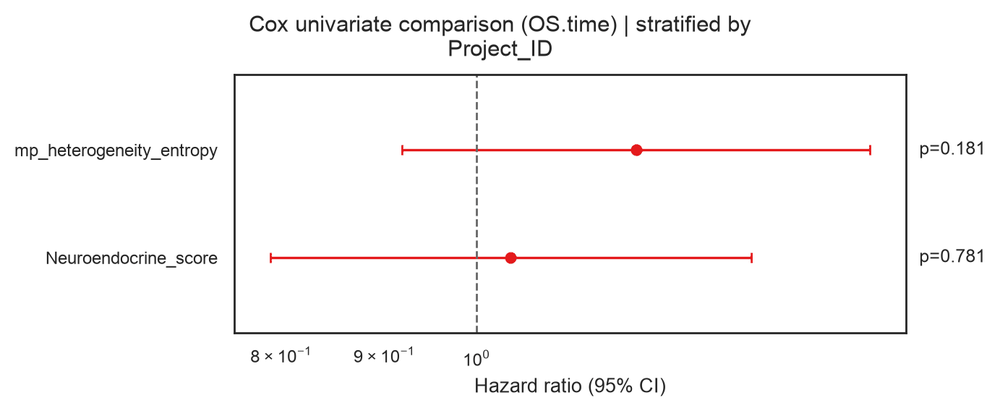

<Axes: xlabel='Hazard ratio (95% CI)'>

In [120]:
bk.pl.cox_forest_from_uns(
    adata,
    uns_key="cox_compare_binary",
    sort_by="HR",
    save=FIGURES + "Fig_CoxForest_compare_binary.svg",
)

### 6.2. Kaplan-Meier curves
Uses module lifetimes: - https://pypi.org/project/Lifetimes/

2×2 interaction” Kaplan–Meier: NE-high/low × heterogeneity-high/low

This is a killer figure for the story (and it’s simple).
If you want, tell me which survival endpoint you prefer (OS, DSS, PFI) and I’ll give you the exact code that:
	•	bins NE and heterogeneity into high/low (e.g., quartiles),
	•	builds 4 groups,
	•	plots KM + Cox interaction

In [121]:
adata_luad = adata[adata.obs.Project_ID == "LUAD"]

               coef        HR  HR_lower_95  HR_upper_95         p
covariate                                                        
x_bin     -0.224885  0.798608     0.484875     1.315339  0.377054
z_bin     -0.573480  0.563561     0.285909     1.110844  0.097651
x_z        0.371776  1.450308     0.518172     4.059254  0.478959


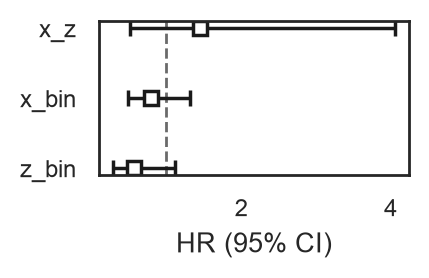

In [122]:
cph, df_used = bk.tl.cox_interaction(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="Proliferation_score",
    z_key="mp_heterogeneity_entropy",
    strata="Project_ID",              # stratified baseline hazards by tumor type
    binning="global",          # or "global"within_group
    q=(0.25, 0.75),
    keep="extremes",
    covariates=None,           # e.g. ["gender", "Age at Diagnosis in Years"] after cleaning
    out_key="cox_NE_x_mphet_OS",
)

# Print HRs
print(adata.uns["cox_NE_x_mphet_OS"]["summary"])

# Forest plot
fig, ax = plt.subplots(figsize=(2,1))
ax = cph.plot(hazard_ratios=True)
ax.figure.savefig(FIGURES + "Fig_Cox_NE_x_Heterogeneity.svg", bbox_inches="tight")
plt.show()

Text(0.5, 1.0, 'Stratified Cox model: NE × Metaprogram heterogeneity')

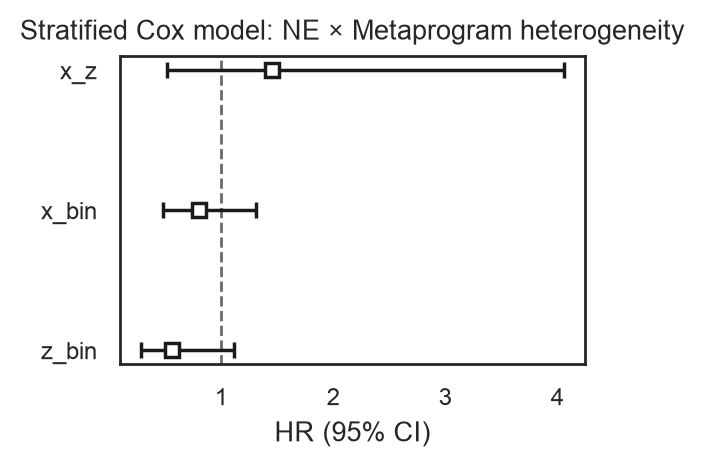

In [123]:
fig, ax = plt.subplots(figsize=(3,2), dpi=200)
ax = cph.plot(hazard_ratios=True)
ax.set_title("Stratified Cox model: NE × Metaprogram heterogeneity")

# ax.figure.savefig("Fig_Cox_NE_x_Heterogeneity.svg", bbox_inches="tight")

#### KM Univariate

Produces:    
	•	KM curves (low vs high).  
	•	Log-rank p-value on plot.   
	•	adata.uns["km_1d"]["logrank_p"] stored for Results text.   

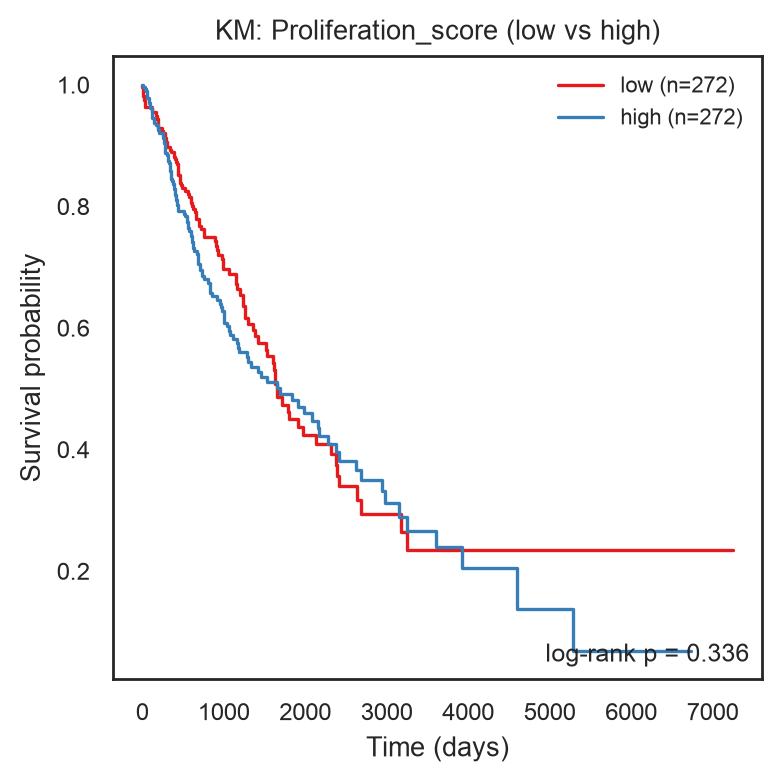

<Axes: title={'center': 'KM: Proliferation_score (low vs high)'}, xlabel='Time (days)', ylabel='Survival probability'>

In [124]:
bk.pl.km_univariate(
    adata,
    x_key="Proliferation_score",
    time_key="OS.time",
    event_key="OS",
    logrank=True,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_Heterogeneity_OS.svg",
)

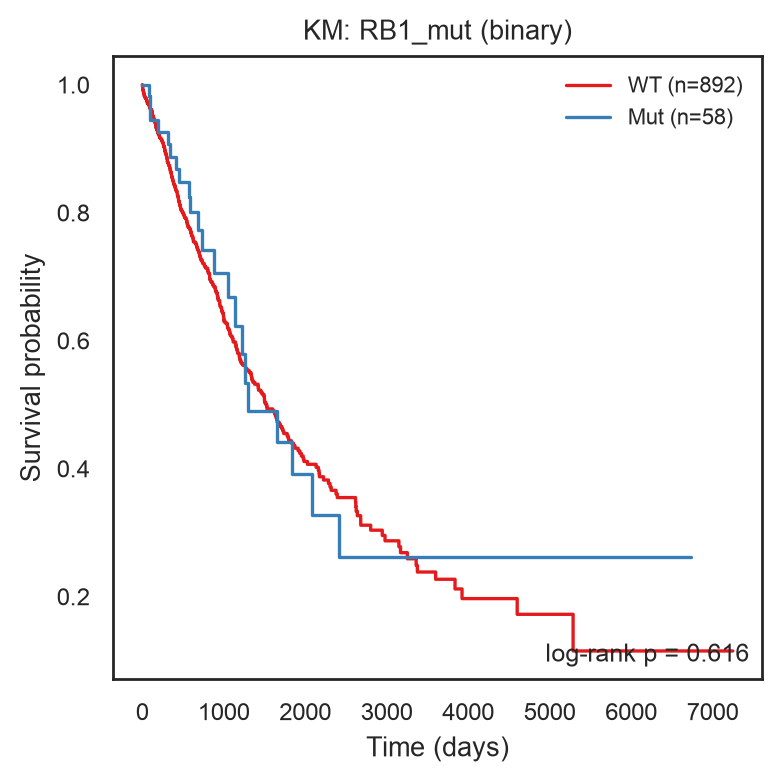

<Axes: title={'center': 'KM: RB1_mut (binary)'}, xlabel='Time (days)', ylabel='Survival probability'>

In [125]:
bk.pl.km_univariate(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="RB1_mut",
    x_source="obs",
    binary_mode="auto",                 # or "force"
    binary_labels=("WT", "Mut"),
    palette={"0":"tab:blue", "1":"tab:red"},
    min_n=20,
    figsize=(4,4),
    logrank=True,
)


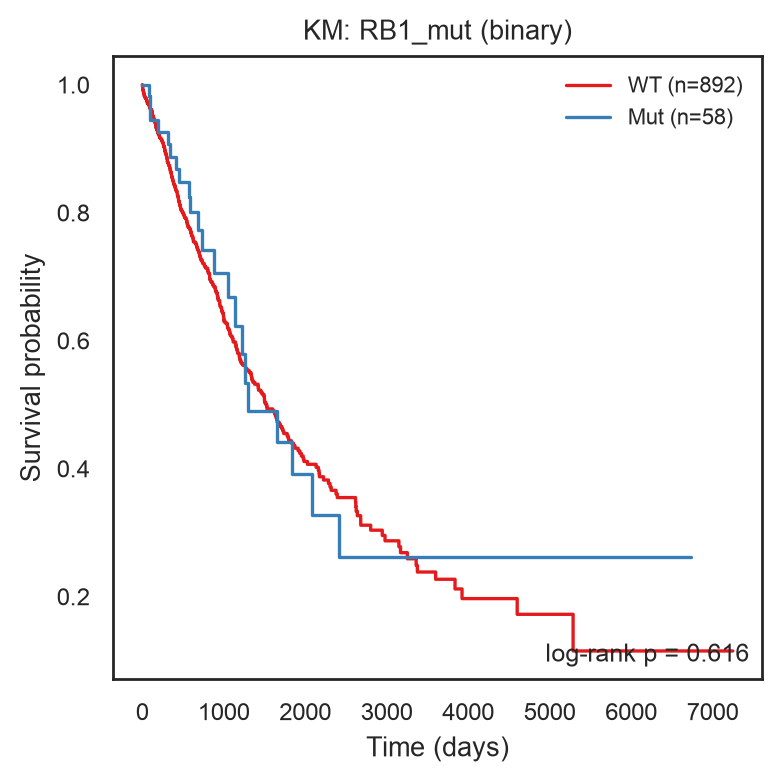

<Axes: title={'center': 'KM: RB1_mut (binary)'}, xlabel='Time (days)', ylabel='Survival probability'>

In [126]:
bk.pl.km_univariate(
    adata,
    x_key="RB1_mut",
    time_key="OS.time",
    event_key="OS",
    logrank=True,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_Heterogeneity_OS.svg",
)

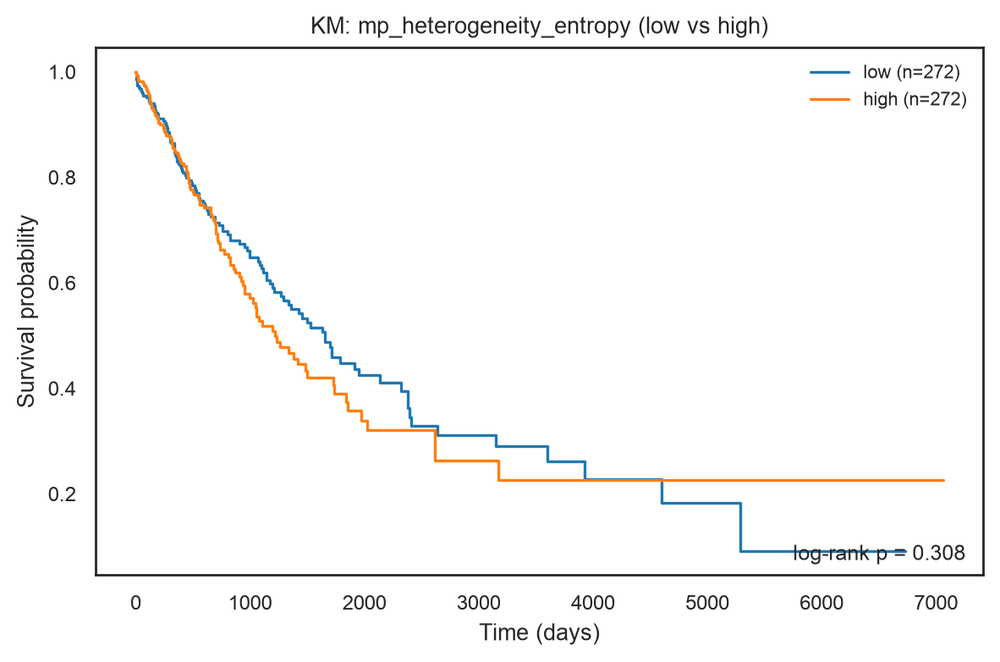

<Axes: title={'center': 'KM: mp_heterogeneity_entropy (low vs high)'}, xlabel='Time (days)', ylabel='Survival probability'>

In [127]:
bk.pl.km_univariate(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="mp_heterogeneity_entropy",
    palette=("tab:blue", "tab:orange"),   # low, high
    logrank=True,
)


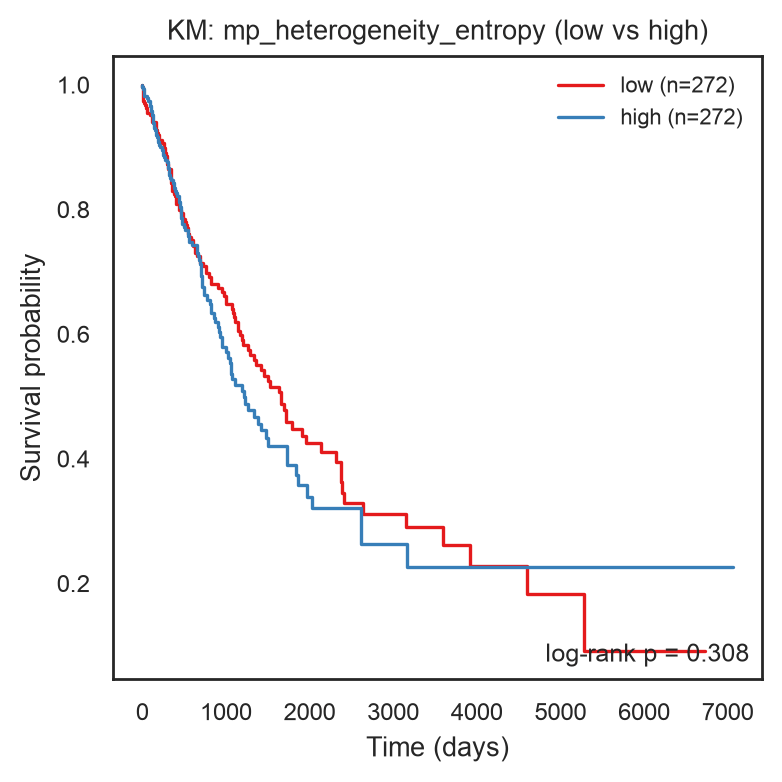

<Axes: title={'center': 'KM: mp_heterogeneity_entropy (low vs high)'}, xlabel='Time (days)', ylabel='Survival probability'>

In [128]:
bk.pl.km_univariate(
    adata,
    x_key="mp_heterogeneity_entropy",
    time_key="OS.time",
    event_key="OS",
    logrank=True,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_Heterogeneity_OS.svg",
)

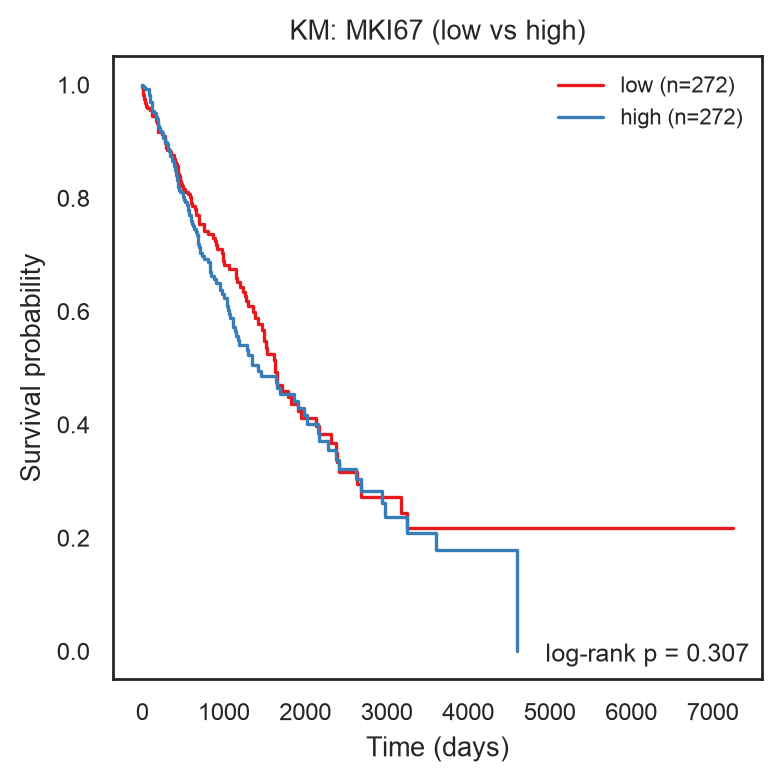

<Axes: title={'center': 'KM: MKI67 (low vs high)'}, xlabel='Time (days)', ylabel='Survival probability'>

In [129]:
bk.pl.km_univariate(
    adata,
    x_key="MKI67",
    x_source="gene",
    time_key="OS.time",
    event_key="OS",
    layer="log1p_cpm",
    group_col=None,
    force_rebin=True,    # if iterating quickly
    logrank=True,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_Heterogeneity_OS.svg",
)


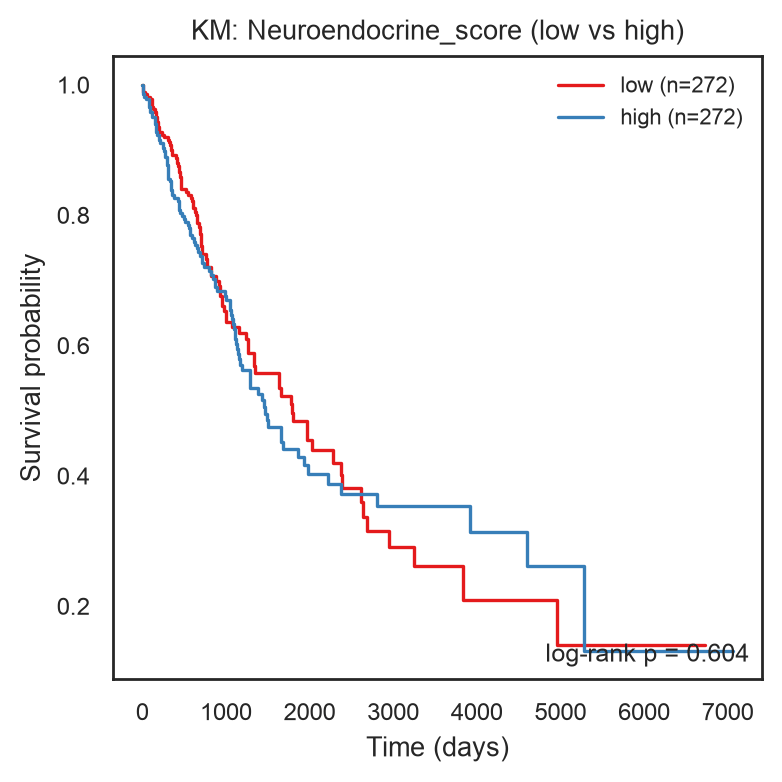

<Axes: title={'center': 'KM: Neuroendocrine_score (low vs high)'}, xlabel='Time (days)', ylabel='Survival probability'>

In [130]:
bk.pl.km_univariate(
    adata,
    x_key="Neuroendocrine_score",
    time_key="OS.time",
    event_key="OS",
    logrank=True,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_Heterogeneity_OS.svg",
)

#### KM 2x2 interaction

#### Cox model stratified by Project_ID (main result)

Uses lifelines

| Term | Meaning | 
| --------- | ----------------------------- |
| NE_bin | Effect of high vs low NE when heterogeneity is low |
| HET_bin |  Effect of high vs low heterogeneity when NE is low |
| NE_x_HET | Extra risk (or protection) when both NE and heterogeneity are high |

If NE_x_HET is significant, that’s your interaction:  
NE programs are particularly deleterious in heterogeneous tumors.

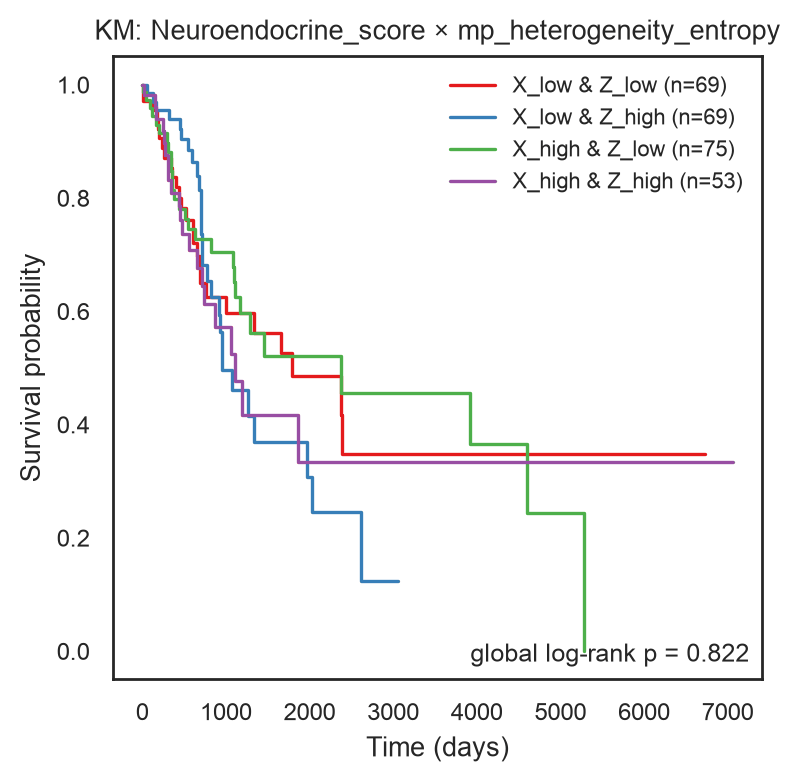

<Axes: title={'center': 'KM: Neuroendocrine_score × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [131]:
bk.pl.km_2x2_interaction(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="Neuroendocrine_score",
    x_source="obs",
    z_key="mp_heterogeneity_entropy",
    z_source="auto",
    layer="log1p_cpm",
    group_col=None,      # strongly recommended
    force_rebin=True,
    logrank=True,
    figsize=(4,4),
)


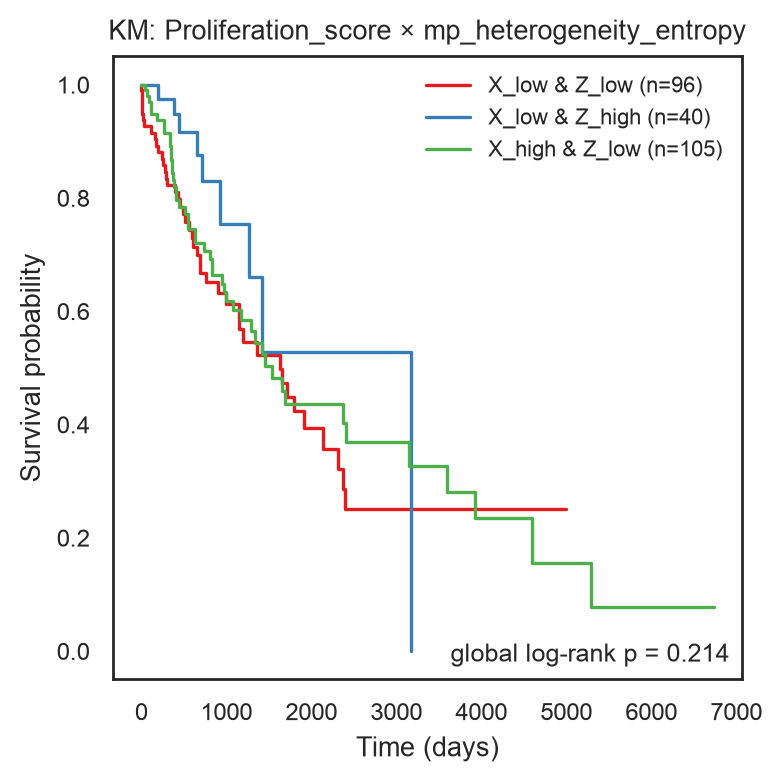

<Axes: title={'center': 'KM: Proliferation_score × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [132]:
bk.pl.km_2x2_interaction(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="Proliferation_score",
    x_source="obs",
    z_key="mp_heterogeneity_entropy",
    z_source="auto",
    layer="log1p_cpm",
    group_col=None,      # strongly recommended
    force_rebin=True,
    logrank=True,
    figsize=(4,4),
)


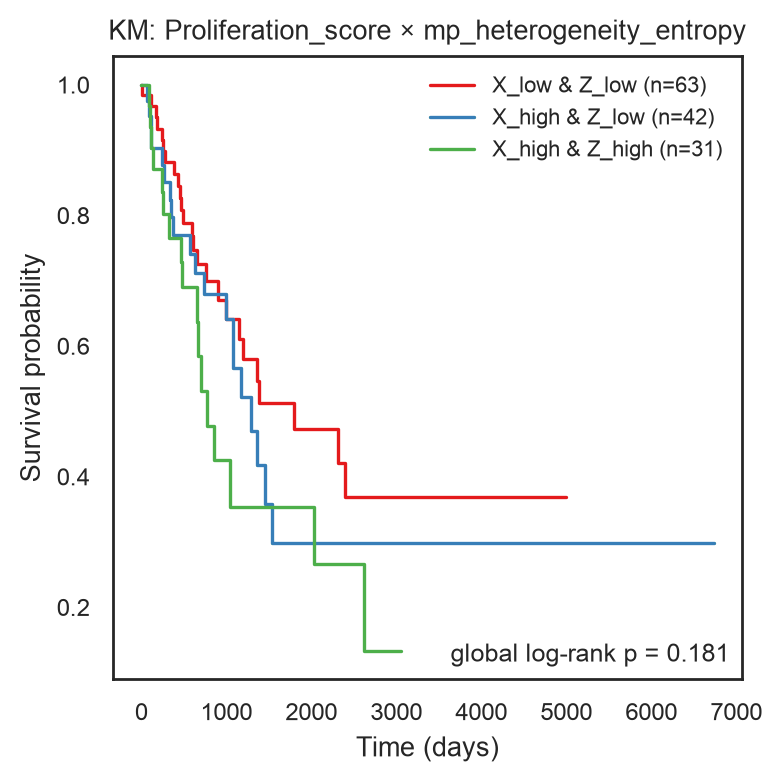

<Axes: title={'center': 'KM: Proliferation_score × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [133]:
bk.pl.km_2x2_interaction(
    adata_luad,
    time_key="OS.time",
    event_key="OS",
    x_key="Proliferation_score",
    x_source="obs",
    z_key="mp_heterogeneity_entropy",
    z_source="auto",
    min_n=15,
    keep="extremes",
    layer="log1p_cpm",
    group_col=None,      # strongly recommended
    force_rebin=True,
    logrank=True,
    figsize=(4,4),
)


Global quantiles (pan-cancer):

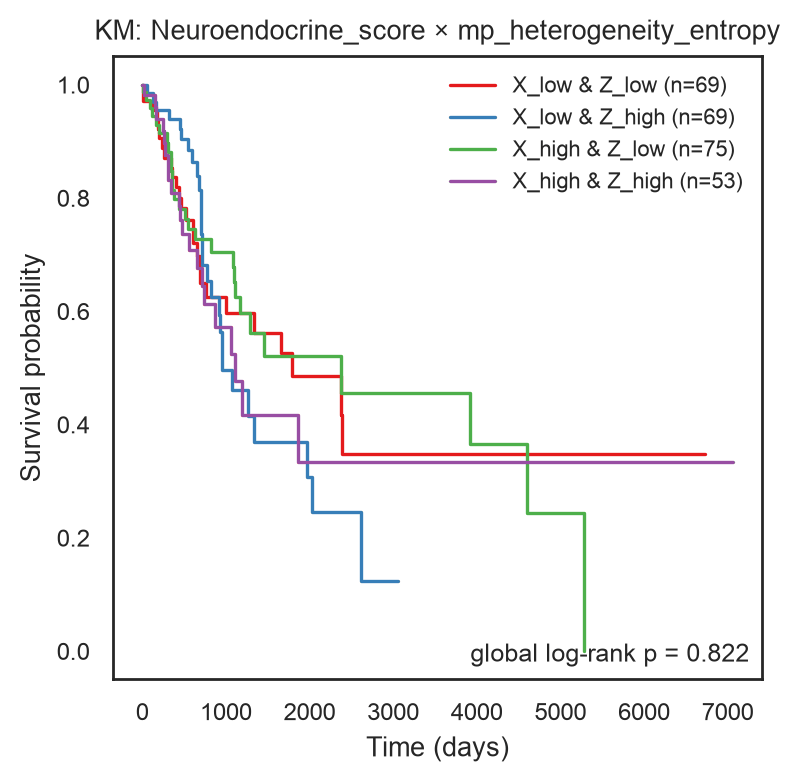

<Axes: title={'center': 'KM: Neuroendocrine_score × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [134]:
bk.pl.km_2x2_interaction(
    adata,
    x_key="Neuroendocrine_score",         # or "NE25_score"
    z_key="mp_heterogeneity_entropy",
    x_source="obs",                      # ["auto", "obs", "gene"] = "auto",
    z_source="obs",                      # ["auto", "obs", "gene"] = "auto",
    time_key="OS.time",
    event_key="OS",
    binning="global",               # "global" | "within_group"
    logrank=True,
    q=(0.25, 0.75),
    min_n=50,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_NE_x_Heterogeneity.svg",
)

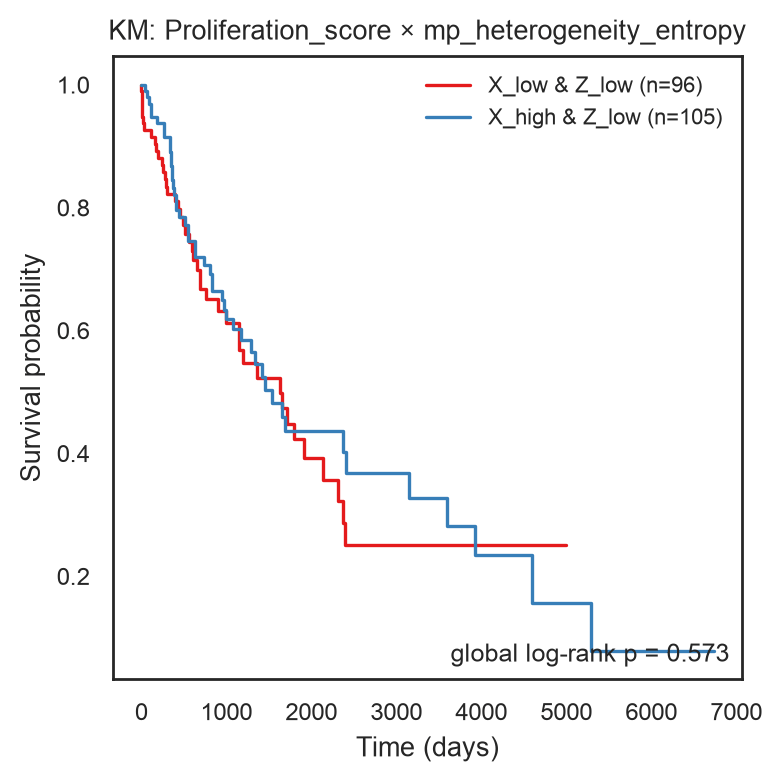

<Axes: title={'center': 'KM: Proliferation_score × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [135]:
bk.pl.km_2x2_interaction(
    adata,
    x_key="Proliferation_score",         # or "NE25_score"
    z_key="mp_heterogeneity_entropy",
    time_key="OS.time",
    event_key="OS",
    binning="global",
    logrank=True,
    q=(0.25, 0.75),
    min_n=50,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_NE_x_Heterogeneity.svg",
)

Within tumor type quantiles (optional, often fairer):

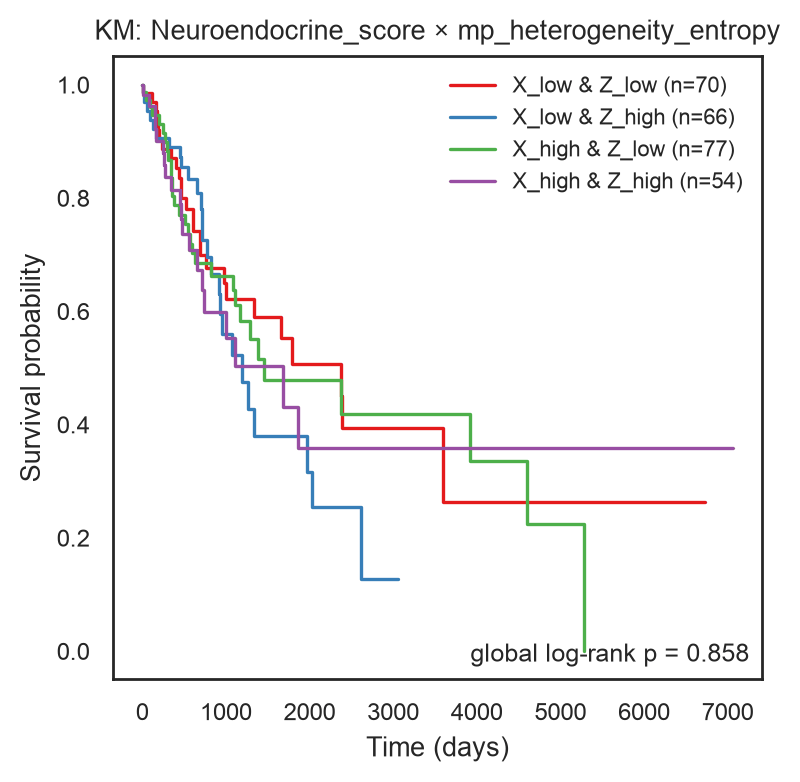

<Axes: title={'center': 'KM: Neuroendocrine_score × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [136]:
bk.pl.km_2x2_interaction(
    adata,
    x_key="Neuroendocrine_score",
    z_key="mp_heterogeneity_entropy",
    time_key="OS.time",
    event_key="OS",
    binning="within_group",
    groupby_for_binning="Project_ID",
    logrank=True,
    q=(0.25, 0.75),
    min_n=40,
    figsize=(4,4),
    save=FIGURES + "Fig_KM_NE_x_Heterogeneity_withinTumor.svg",
)

Use it also for interaction between genes

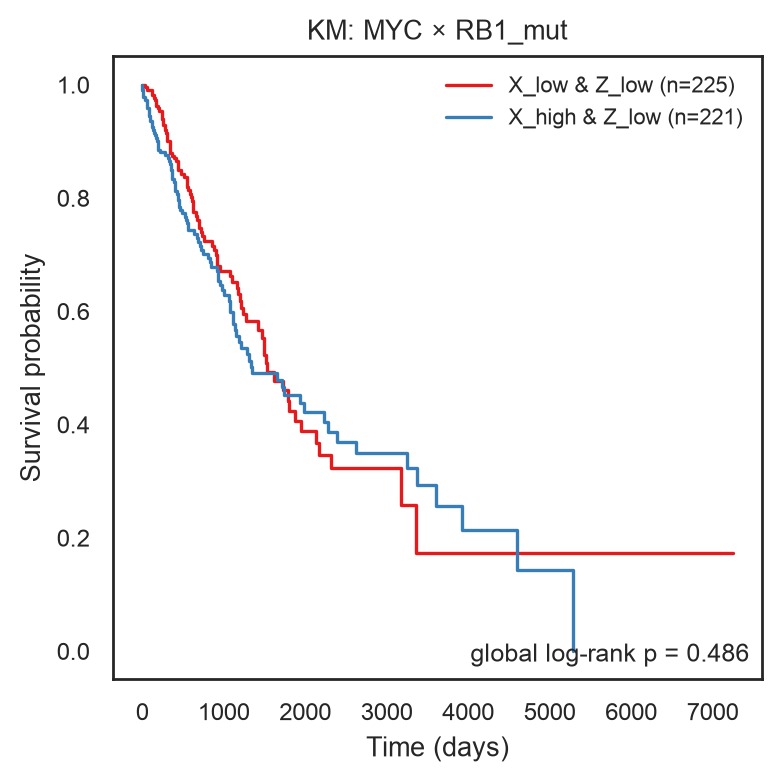

<Axes: title={'center': 'KM: MYC × RB1_mut'}, xlabel='Time (days)', ylabel='Survival probability'>

In [137]:
bk.pl.km_2x2_interaction(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="MYC",
    x_source="gene",
    z_key="RB1_mut",
    z_source="obs",
    layer="log1p_cpm",
    group_col=None,      # strongly recommended
    force_rebin=True,
    logrank=True,
    figsize=(4,4),
)


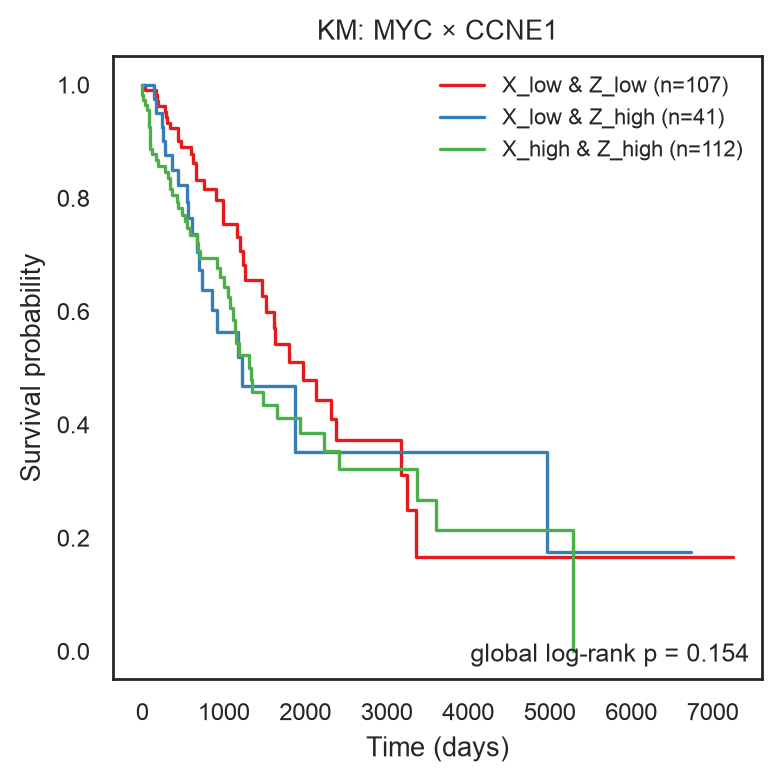

<Axes: title={'center': 'KM: MYC × CCNE1'}, xlabel='Time (days)', ylabel='Survival probability'>

In [138]:
bk.pl.km_2x2_interaction(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="MYC",
    x_source="gene",
    z_key="CCNE1",
    z_source="gene",
    layer="log1p_cpm",
    group_col=None,      # strongly recommended
    force_rebin=True,
    logrank=True,
    figsize=(4,4),
)


You can easily extend the model:    
`formula = "NE_bin + HET_bin + NE_x_HET + age + gender"`

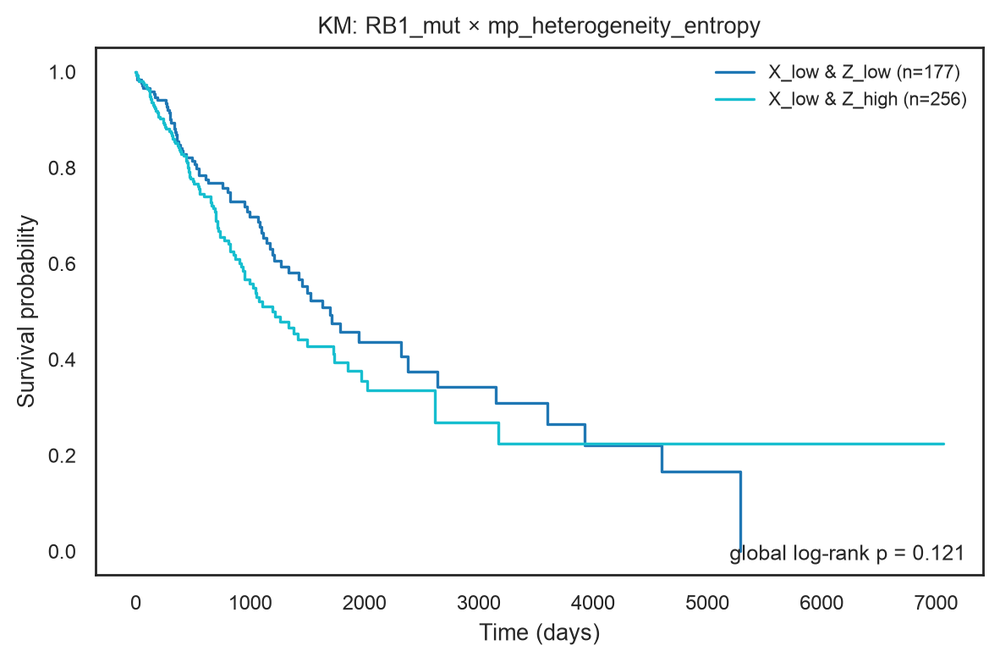

<Axes: title={'center': 'KM: RB1_mut × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [139]:
#Change palette in km_2x2:
bk.pl.km_2x2_interaction(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="RB1_mut",
    x_source="obs",
    x_binary_mode="auto",
    x_binary_labels=("WT","Mut"),
    z_key="mp_heterogeneity_entropy",
    z_source="obs",
    palette={
        "X_low & Z_low": "tab:blue",
        "X_low & Z_high": "tab:cyan",
        "X_high & Z_low": "tab:orange",
        "X_high & Z_high": "tab:red",
    },
    min_n=30,
    logrank=True,
    force_rebin=True,
)


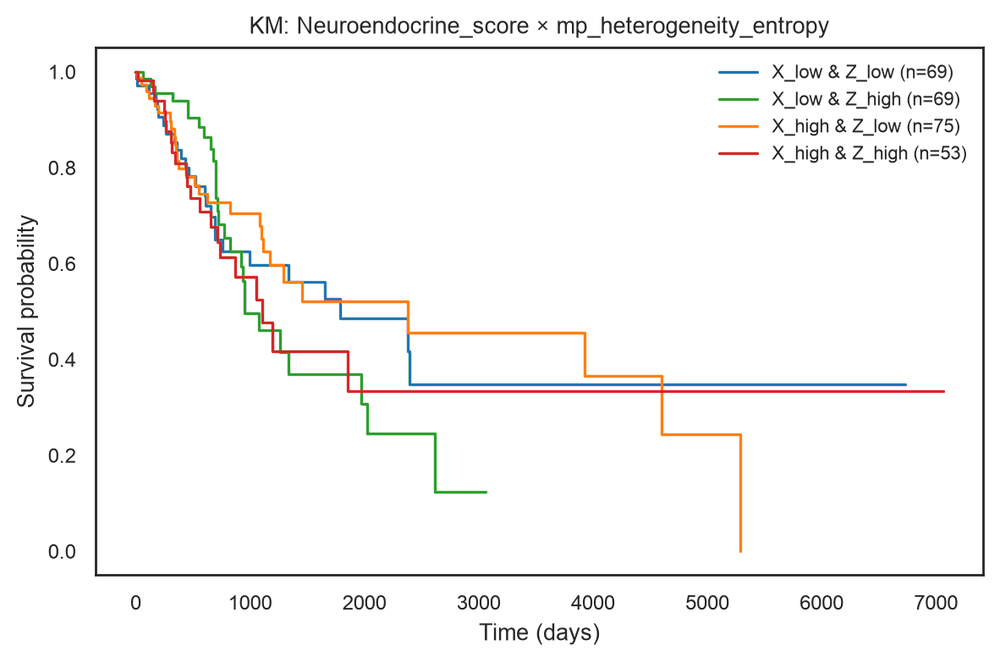

<Axes: title={'center': 'KM: Neuroendocrine_score × mp_heterogeneity_entropy'}, xlabel='Time (days)', ylabel='Survival probability'>

In [140]:
bk.pl.km_2x2_interaction(
    adata,
    time_key="OS.time",
    event_key="OS",
    x_key="Neuroendocrine_score",
    z_key="mp_heterogeneity_entropy",
    palette=("tab:blue", "tab:green", "tab:orange", "tab:red"),
)
